# Load data and model

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import interp1d
from scipy.spatial.distance import pdist, squareform
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from matplotlib.collections import LineCollection
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge, RidgeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, balanced_accuracy_score
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import matplotlib.gridspec as gridspec
from scipy.stats import wilcoxon
from scipy.spatial.distance import cdist
from scipy.stats import spearmanr

# sys.path.append(os.path.expanduser('~/Documents/code/utils'))
# sys.path.append(os.path.expanduser('~/Documents/code/digitalbat'))
sys.path.append('/mnt/scratch09/yongrong/projects/bat-intelligence/src/digitalbat')

from digitalbat.utility.utils import (
    set_random_state, bat_palette, parse_bat, corr,
    poisson_fde_population, poisson_fde_population_filtered,
)
from digitalbat.datasets.data import bat_data_loader
from digitalbat.datasets.defaults import DEFAULT_SESSION_NAMES, make_data_config
from digitalbat.datasets.kinematics import make_joint_dataloaders
from digitalbat.models.joint import JointMaskedTransformer
from digitalbat.utility.utils import list_pad_concatenate, compute_angles, generate_landmark_dicts
from digitalbat.utility.utils import stars_for_p, add_significance_bracket
from digitalbat.utility.utils import FlightDMD, FlightDMDAnalyzer, FlightDMDPostAnalysis
from digitalbat.utility.utils import generate_rate_map, generate_2d_rate_map, BatSpatialInfo, BatRateMapSim

# import notebook_helpers as nh
# import plotting_helpers as ph
# ph.set_pub_style()
# ph.FIG_DIR = Path('out/figures')

seed = 1
set_random_state(seed)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

# # Canonical display name for the joint encode/decode transformer (used in all labels).
# HIPPO_NEDS = 'Hippo-NEDS'

device: cuda


In [2]:
# for plot figures
# sns.set_theme(context='talk', style='ticks')
plt.rcParams.update({'figure.max_open_warning': 0})
#Output matplotlib figure to SVG with text as text, not curves
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['pdf.fonttype'] = 42   # editable text in Illustrator

from digitalbat.utility.utils import bat_palette

def route_palette():
    """Return a `{route_label: rgb_or_color_name}` dict in canonical order."""
    ROUTE_LABELS = ["Rew->Rew", "Rew->Per", "Per->Rew", "Per->Per", "Other"]
    ROUTE_COLORS = ['firebrick', 'darkorange', 'forestgreen', 'steelblue', 'gray']
    
    return {label: color for label, color in zip(ROUTE_LABELS, ROUTE_COLORS)}

def landmark_palette():
    """Return a `{landmark_label: rgb_or_color_name}` dict in canonical order."""
    LANDMARK_LABELS = ["Start@Rew", "End@Rew", "Start@Per", "End@Per", "Start@Other", "End@Other"]
    # Choosing an intuitive color scheme (greens for start, reds/corals for end, gray for other)
    LANDMARK_COLORS = ['forestgreen', 'firebrick', 'mediumseagreen', 'tomato', 'darkgray', 'lightgray']
    return {label: color for label, color in zip(LANDMARK_LABELS, LANDMARK_COLORS)}

In [3]:
# 17 DEFAULT_SESSIONS, position-only (behavior_dim == 3).
EXCLUDED_SESSIONS = {'Dataset_3_14543_240419'}
session_names = [s for s in DEFAULT_SESSION_NAMES if s not in EXCLUDED_SESSIONS]

PARENT_FOLDER = '/mnt/at-globusshare/Users/Yongrong/'
max_acceleration = 50.0
data_config = make_data_config(session_names=session_names, parent_folder=PARENT_FOLDER, max_acceleration=max_acceleration)
session_names = data_config['session_names']
bin_width = data_config['bin_width']

# Single load in the joint model's *training* universe. make_joint_dataloaders
# loads once (kinematics on) and returns the position-only view `dl_pos` plus the
# shared meta. We use this ONE universe for BOTH the encode and decode arms so
# every analysis shares one flight_path_index (no cross-universe remapping). The
# tradeoff vs the plain position-only loader is that a few tail flights with short
# IMU are dropped — negligible, and it matches how the model was trained.
dataloaders, _dl_kin, unit_num_dict, meta_info_dict = make_joint_dataloaders(data_config)
behavior_dim = 3

# bats = ph.bat_order()
# BAT_PALETTE = ph.bat_pal()
n_neurons_total = sum(unit_num_dict.values())
print(f'{len(session_names)} sessions | {n_neurons_total} neurons | behavior_dim={behavior_dim}')
# print('neurons/session:', {s: unit_num_dict[s] for s in session_names[:3]}, '...')

  Acceleration filter: removed 1/136 flights (peak |acc| > 50.0 m/s²)
  Acceleration filter: removed 9/154 flights (peak |acc| > 50.0 m/s²)
  Acceleration filter: removed 4/131 flights (peak |acc| > 50.0 m/s²)
  Acceleration filter: removed 1/79 flights (peak |acc| > 50.0 m/s²)
  Acceleration filter: removed 1/78 flights (peak |acc| > 50.0 m/s²)
  Acceleration filter: removed 1/77 flights (peak |acc| > 50.0 m/s²)
  Acceleration filter: removed 4/82 flights (peak |acc| > 50.0 m/s²)
  Acceleration filter: removed 1/98 flights (peak |acc| > 50.0 m/s²)
  Acceleration filter: removed 4/112 flights (peak |acc| > 50.0 m/s²)
17 sessions | 3080 neurons | behavior_dim=3


In [4]:
dataloaders

{'train': {'Dataset_3_14543_240420': <torch.utils.data.dataloader.DataLoader at 0x7f72f03ceae0>,
  'Dataset_3_14543_240421': <torch.utils.data.dataloader.DataLoader at 0x7f72f03cce90>,
  'Dataset_3_29959_240402': <torch.utils.data.dataloader.DataLoader at 0x7f72f03cd850>,
  'Dataset_3_29959_240403': <torch.utils.data.dataloader.DataLoader at 0x7f72f03cf980>,
  'Dataset_3_29959_240404': <torch.utils.data.dataloader.DataLoader at 0x7f72f03cc3e0>,
  'Dataset_2_14445_231208': <torch.utils.data.dataloader.DataLoader at 0x7f72f03cf830>,
  'Dataset_2_14445_231209': <torch.utils.data.dataloader.DataLoader at 0x7f72f03cfa70>,
  'Dataset_1_32622_231009': <torch.utils.data.dataloader.DataLoader at 0x7f72f03cc650>,
  'Dataset_1_32622_231010': <torch.utils.data.dataloader.DataLoader at 0x7f72f03ceb40>,
  'Dataset_1_32622_231007': <torch.utils.data.dataloader.DataLoader at 0x7f72f03cf4a0>,
  'Dataset_2_14611_231208': <torch.utils.data.dataloader.DataLoader at 0x7f72f03cee10>,
  'Dataset_2_14611_2312

In [5]:
unit_num_dict, meta_info_dict.keys()

({'Dataset_3_14543_240420': 126,
  'Dataset_3_14543_240421': 100,
  'Dataset_3_29959_240402': 317,
  'Dataset_3_29959_240403': 191,
  'Dataset_3_29959_240404': 190,
  'Dataset_2_14445_231208': 237,
  'Dataset_2_14445_231209': 168,
  'Dataset_1_32622_231009': 95,
  'Dataset_1_32622_231010': 54,
  'Dataset_1_32622_231007': 167,
  'Dataset_2_14611_231208': 236,
  'Dataset_2_14611_231209': 186,
  'Dataset_3_00000_240402': 394,
  'Dataset_3_00000_240403': 207,
  'Dataset_3_00000_240404': 147,
  'Dataset_3_00000_240405': 122,
  'Dataset_3_29959_240405': 143},
 dict_keys(['r_lim', 'flight_type_test_indomain', 'flight_type_test_ood', 'behavior_mean', 'behavior_std', 'spike_std', 'spatial_centers_sigma', 'pType', 'probe_id', 'neuron_position']))

In [6]:
# --- Consensus model: the single joint encode/decode transformer used paper-wide
# (6-masking infill/forecast finetune; joint-encode-decode.ipynb §6.4).
JOINT_CKPT = ('./out/joint/joint_v2_cross1000_kin0_L4_d64_ff64_lam0.68_pw0.36_identity'
              '_we2.8_wd2.2_wa0.31_n17.pth')
JOINT_PARAMS = dict(num_layers=4, latent_dim=64, num_heads=4, ff_dim=64, dropout=0.2)
INPUT_TRANSFORM = 'identity'


def joint_session_room(s):
    """3-config room map (matches joint-encode-decode.ipynb `session_room`)."""
    if '_fs' in s:
        return 'krishna_fs'
    if s.startswith('Dataset_2_'):
        return 'dataset_2'
    return 'lab'


session_to_room = {s: joint_session_room(s) for s in unit_num_dict}

set_random_state(seed)
if os.path.exists(JOINT_CKPT):
    joint_model = JointMaskedTransformer(
        unit_num_dict, behavior_dim=3, input_transform=INPUT_TRANSFORM,
        session_to_room=session_to_room, **JOINT_PARAMS).to(device)
    joint_model.load_state_dict(torch.load(JOINT_CKPT, map_location=device))
    joint_model = joint_model.eval()
else:
    # Train-if-missing: 200-trial Optuna search (use_kinematics=False, fde_weight=0.5),
    # then train the winner. Reproduces the consensus checkpoint named above.
    from digitalbat.training.joint_trainer import ensure_joint_model
    joint_model, _jp, JOINT_CKPT = ensure_joint_model(
        dataloaders, unit_num_dict, session_to_room, meta_info_dict, device,
        seed=seed, out_dir='./out/joint', n_trials=200)
    JOINT_PARAMS = dict(num_layers=_jp['num_layers'], latent_dim=_jp['latent_dim'],
                        num_heads=4, ff_dim=_jp['ff_dim'], dropout=_jp['dropout'])

# Encode and decode arms share ONE flight universe (see the data-load cell), so the
# decode-arm loaders/meta are simply the shared ones — no separate universe.
joint_loaders, joint_meta = dataloaders, meta_info_dict
print('consensus joint model ready:', JOINT_CKPT)

consensus joint model ready: ./out/joint/joint_v2_cross1000_kin0_L4_d64_ff64_lam0.68_pw0.36_identity_we2.8_wd2.2_wa0.31_n17.pth


In [7]:
joint_model

JointMaskedTransformer(
  (spike_readin): ModuleDict(
    (Dataset_3_14543_240420): Linear(in_features=126, out_features=64, bias=True)
    (Dataset_3_14543_240421): Linear(in_features=100, out_features=64, bias=True)
    (Dataset_3_29959_240402): Linear(in_features=317, out_features=64, bias=True)
    (Dataset_3_29959_240403): Linear(in_features=191, out_features=64, bias=True)
    (Dataset_3_29959_240404): Linear(in_features=190, out_features=64, bias=True)
    (Dataset_2_14445_231208): Linear(in_features=237, out_features=64, bias=True)
    (Dataset_2_14445_231209): Linear(in_features=168, out_features=64, bias=True)
    (Dataset_1_32622_231009): Linear(in_features=95, out_features=64, bias=True)
    (Dataset_1_32622_231010): Linear(in_features=54, out_features=64, bias=True)
    (Dataset_1_32622_231007): Linear(in_features=167, out_features=64, bias=True)
    (Dataset_2_14611_231208): Linear(in_features=236, out_features=64, bias=True)
    (Dataset_2_14611_231209): Linear(in_featur

# Generate features for analysis

In [8]:
# --- Extract latent representations via forward hook ---
joint_model.eval()

latent_dict = {}  # session -> (n_timepoints, latent_dim), encode
latent_d_dict = {}  # session -> (n_timepoints, latent_dec_dim), decode
xyz_dict = {}     # session -> (n_timepoints, 3)
rel_azimuth_dict = {}  # session -> (n_timepoints,), head direction, -180 deg ~ 180 deg
rel_elevation_dict = {} # session -> (n_timepoints,), head direction, -90 deg ~ 90 deg
flight_id_dict = {}  # session -> (n_timepoints,)
rel_time_dict = {}   # session -> (n_timepoints,) in [0, 1]
accel_dict = {}      # session -> (n_timepoints,) total acceleration
speed_dict = {}      # session -> (n_timepoints,) L2 velocity norm
cluster_dict = {}    # session -> (n_timepoints,) flight cluster type
session_label_dict = {}  # session -> (n_timepoints,) session name string
true_spike_dict = {} # session -> (n_timepoints, n_neurons), recorded spike counts
# saliency_dict = {} # session -> (n_timepoints_resp, n_timepoints_loc, n_neurons)

dt = data_config['bin_width']

for session_name, session_data in dataloaders['test'].items():
    latents_session, xyz_session, fid_session, rtime_session, accel_session, speed_session, cluster_session, slabel_session = [], [], [], [], [], [], [], []
    latents_d_session = []
    true_spike_session = []
    rel_azimuth_session, rel_elevation_session = [], []
    # saliency_session = []

    with torch.no_grad():
        for batch in session_data:
            mask = batch.mask.to(device); T = batch.spike.shape[1]
            nt = batch.mask.clone().to(device); bt = torch.zeros_like(nt)
            # encode pass
            spike0 = torch.zeros_like(batch.spike.to(device))
            _, _, xfull = joint_model(session_name, spike0, batch.behavior.to(device), mask, nt, bt)
            h = xfull[:, :T] 
            m = batch.mask.bool()
            latents_session.append(h[m.to(device)].cpu().numpy())
            # decode pass: real spikes visible, behaviour masked -> decode latent
            behavior0 = torch.zeros_like(batch.behavior.to(device))
            _, _, xfull_d = joint_model(session_name, batch.spike.to(device), behavior0, mask, torch.zeros_like(mask), mask)
            h_d = xfull_d[:, :T] # encode space too: neural tokens x[:, :T] (decode pass)
            latents_d_session.append(h_d[m.to(device)].cpu().numpy())

            pos = batch.behavior[:, :, :3].numpy()  # (B, T, 3)
            # Convert z-scored position back to meters
            bm = meta_info_dict['behavior_mean'][session_name]  # (1, 1, D)
            bs = meta_info_dict['behavior_std'][session_name]
            pos_meters = pos * bs[0, 0, :3] + bm[0, 0, :3]
            xyz_session.append(pos_meters[m.cpu().numpy()])

            # azimuth and elevation
            head_dir = np.diff(pos, axis=1, prepend=0) # pos - pos[:, 0, :][:, None, :]
            head_dir = head_dir[m.cpu().numpy()]
            rel_azimuth, rel_elevation = compute_angles(head_dir)
            rel_azimuth_session.append(rel_azimuth)
            rel_elevation_session.append(rel_elevation)
            
            # Total velocity and acceleration via np.gradient
            spd = np.zeros(pos.shape[:2])  # (B, T)
            acc = np.zeros(pos.shape[:2])  # (B, T)
            for bi in range(pos.shape[0]):
                vel = np.gradient(pos[bi], dt, axis=0)   # (T, 3)
                a = np.gradient(vel, dt, axis=0)          # (T, 3)
                spd[bi] = np.linalg.norm(vel, axis=1)
                acc[bi] = np.linalg.norm(a, axis=1)
            speed_session.append(spd[m.cpu().numpy()])
            accel_session.append(acc[m.cpu().numpy()])

            # Flight path index per valid timestep
            fpi = batch.flight_path_index  # (B,)
            fpi_expanded = fpi.unsqueeze(1).expand_as(batch.mask)  # (B, T)
            fid_session.append(fpi_expanded[m].numpy())
            # Flight cluster type per valid timestep
            fti = batch.flight_type_index  # (B,)
            fti_expanded = fti.unsqueeze(1).expand_as(batch.mask)  # (B, T)
            cluster_session.append(fti_expanded[m].numpy())
            # Session label per valid timestep
            slabel_session.append(np.full(m.sum().item(), session_name))
            # Relative time within each flight: 0 at start, 1 at end
            T = batch.mask.shape[1]
            t_grid = torch.arange(T, dtype=torch.float32).unsqueeze(0).expand_as(batch.mask)
            n_valid = batch.mask.sum(dim=1, keepdim=True).clamp(min=2)  # (B, 1)
            rel_t = t_grid / (n_valid - 1)
            rtime_session.append(rel_t[m].numpy())

            # recorded spike counts
            true_spike_session.append(batch.spike.detach()[batch.mask.detach() == 1.0].cpu().numpy()) # (T, Neuron)

    latent_dict[session_name] = np.concatenate(latents_session)
    latent_d_dict[session_name] = np.concatenate(latents_d_session)
    xyz_dict[session_name] = np.concatenate(xyz_session)
    rel_azimuth_dict[session_name] = np.concatenate(rel_azimuth_session)
    rel_elevation_dict[session_name] = np.concatenate(rel_elevation_session)
    flight_id_dict[session_name] = np.concatenate(fid_session)
    rel_time_dict[session_name] = np.concatenate(rtime_session)
    accel_dict[session_name] = np.concatenate(accel_session)
    speed_dict[session_name] = np.concatenate(speed_session)
    cluster_dict[session_name] = np.concatenate(cluster_session)
    session_label_dict[session_name] = np.concatenate(slabel_session)
    true_spike_dict[session_name] = np.concatenate(true_spike_session)

# Concatenate across all sessions
all_latents = np.concatenate(list(latent_dict.values()))
all_latents_dec = np.concatenate(list(latent_d_dict.values()))
all_xyz = np.concatenate(list(xyz_dict.values()))
all_rel_azimuth = np.concatenate(list(rel_azimuth_dict.values()))
all_rel_elevation = np.concatenate(list(rel_elevation_dict.values()))
all_rel_time = np.concatenate(list(rel_time_dict.values()))
all_accel = np.concatenate(list(accel_dict.values()))
all_speed = np.concatenate(list(speed_dict.values()))
all_cluster = np.concatenate(list(cluster_dict.values()))
all_session = np.concatenate(list(session_label_dict.values()))
all_flight_id = np.concatenate(list(flight_id_dict.values()))
all_true_spike = list_pad_concatenate(list(true_spike_dict.values()))
# all_saliency = list_pad_concatenate(list(saliency_dict.values()))

# Derived categorical labels
import re
all_bat = np.array([re.search(r'_(\d{5})_', s).group(1) for s in all_session])
all_cluster_session = np.array([f'{s}_c{int(c)}' for s, c in zip(all_session, all_cluster)])
all_flight_session = np.array([f'{s}_f{int(f)}' for s, f in zip(all_session, all_flight_id)])
print(f'Latent shape: {all_latents.shape}, Latent_dec shape: {all_latents_dec.shape}, XYZ shape: {all_xyz.shape}, all_true_spike.shape: {all_true_spike.shape}')
print(f'Unique bats: {len(np.unique(all_bat))}, sessions: {len(np.unique(all_session))}, '
      f'cluster-sessions: {len(np.unique(all_cluster_session))}, flight-sessions: {len(np.unique(all_flight_session))}')
print(f'all_cluster_session: {all_cluster_session}')

Latent shape: (8072, 64), Latent_dec shape: (8072, 64), XYZ shape: (8072, 3), all_true_spike.shape: (8072, 394)
Unique bats: 6, sessions: 17, cluster-sessions: 131, flight-sessions: 278
all_cluster_session: ['Dataset_3_14543_240420_c3' 'Dataset_3_14543_240420_c3'
 'Dataset_3_14543_240420_c3' ... 'Dataset_3_29959_240405_c6'
 'Dataset_3_29959_240405_c6' 'Dataset_3_29959_240405_c6']


In [9]:
# PCA
pca3 = PCA(n_components=3).fit(all_latents)
all_latents_pca3 = pca3.transform(all_latents)
print(f'PCA: first 3 PCs explain {pca3.explained_variance_ratio_.sum():.1%} of variance')

pca3 = PCA(n_components=3).fit(all_latents_dec)
all_latents_dec_pca3 = pca3.transform(all_latents_dec)
print(f'PCA: first 3 PCs explain {pca3.explained_variance_ratio_.sum():.1%} of variance')

PCA: first 3 PCs explain 27.4% of variance
PCA: first 3 PCs explain 29.0% of variance


In [10]:
from digitalbat.utility.utils import decode_spikes_to_latent
all_spike_in_latent = decode_spikes_to_latent(all_true_spike, all_latents, all_session)
# PCA
pca3 = PCA(n_components=3).fit(all_spike_in_latent)
all_spike_in_latent_pca3 = pca3.transform(all_spike_in_latent)
print(f'PCA: first 3 PCs explain {pca3.explained_variance_ratio_.sum():.1%} of variance')

Starting latent reconstruction across 17 sessions...



Session Dataset_1_32622_231007 | Neurons: 167 | Mean Test $R^2$: 0.373
Session Dataset_1_32622_231009 | Neurons: 95 | Mean Test $R^2$: 0.357
Session Dataset_1_32622_231010 | Neurons: 54 | Mean Test $R^2$: 0.373
Session Dataset_2_14445_231208 | Neurons: 237 | Mean Test $R^2$: 0.518
Session Dataset_2_14445_231209 | Neurons: 168 | Mean Test $R^2$: 0.489
Session Dataset_2_14611_231208 | Neurons: 236 | Mean Test $R^2$: 0.467
Session Dataset_2_14611_231209 | Neurons: 186 | Mean Test $R^2$: 0.543
Session Dataset_3_00000_240402 | Neurons: 394 | Mean Test $R^2$: 0.579
Session Dataset_3_00000_240403 | Neurons: 207 | Mean Test $R^2$: 0.563
Session Dataset_3_00000_240404 | Neurons: 147 | Mean Test $R^2$: 0.459
Session Dataset_3_00000_240405 | Neurons: 122 | Mean Test $R^2$: 0.373
Session Dataset_3_14543_240420 | Neurons: 126 | Mean Test $R^2$: 0.454
Session Dataset_3_14543_240421 | Neurons: 100 | Mean Test $R^2$: 0.423
Session Dataset_3_29959_240402 | Neurons: 317 | Mean Test $R^2$: 0.393
Session 

In [11]:
# landmark locations (reward and perch) in physical space 
# Dataset1 and Dataset3 use the same landmarks
# Dataset1 and Dataset3 have two reward locations and one perch location (though two are given, but we use a Logical OR 
# operation to include any locations with a Euclidean distance < 0.3 m)
landmark_phy = {
    'Dataset_1': dict(
        rew_locs=np.array([
            [2.80, -0.86, 1.57],
            [2.75,  0.96, 1.57],
        ]),
        perch_locs=np.array([
            [-2.55, 1.57, 1.82],
            [-1.98, 2.08, 1.74],
        ]),
    ),
    'Dataset_3': dict(
        rew_locs=np.array([
            [2.80, -0.86, 1.57],
            [2.75,  0.96, 1.57],
        ]),
        perch_locs=np.array([
            [-2.55, 1.57, 1.82],
            [-1.98, 2.08, 1.74],
        ]),
    ),
    'Dataset_2': dict(
        rew_locs=np.array([
            [-3.00, 0.70, 1.90],
        ]),
        perch_locs=np.array([
            [-3.20, 1.80, 2.20],
        ]),
    ),
}

threshold = 0.6
reward_dict, perch_dict = generate_landmark_dicts(xyz_dict, landmark_phy, threshold=threshold)
all_reward = np.concatenate(list(reward_dict.values()))
all_perch = np.concatenate(list(perch_dict.values()))

# Behaviorally grounded place fields

## Examples

Session: Dataset_1_32622_231009; Neuron: 13


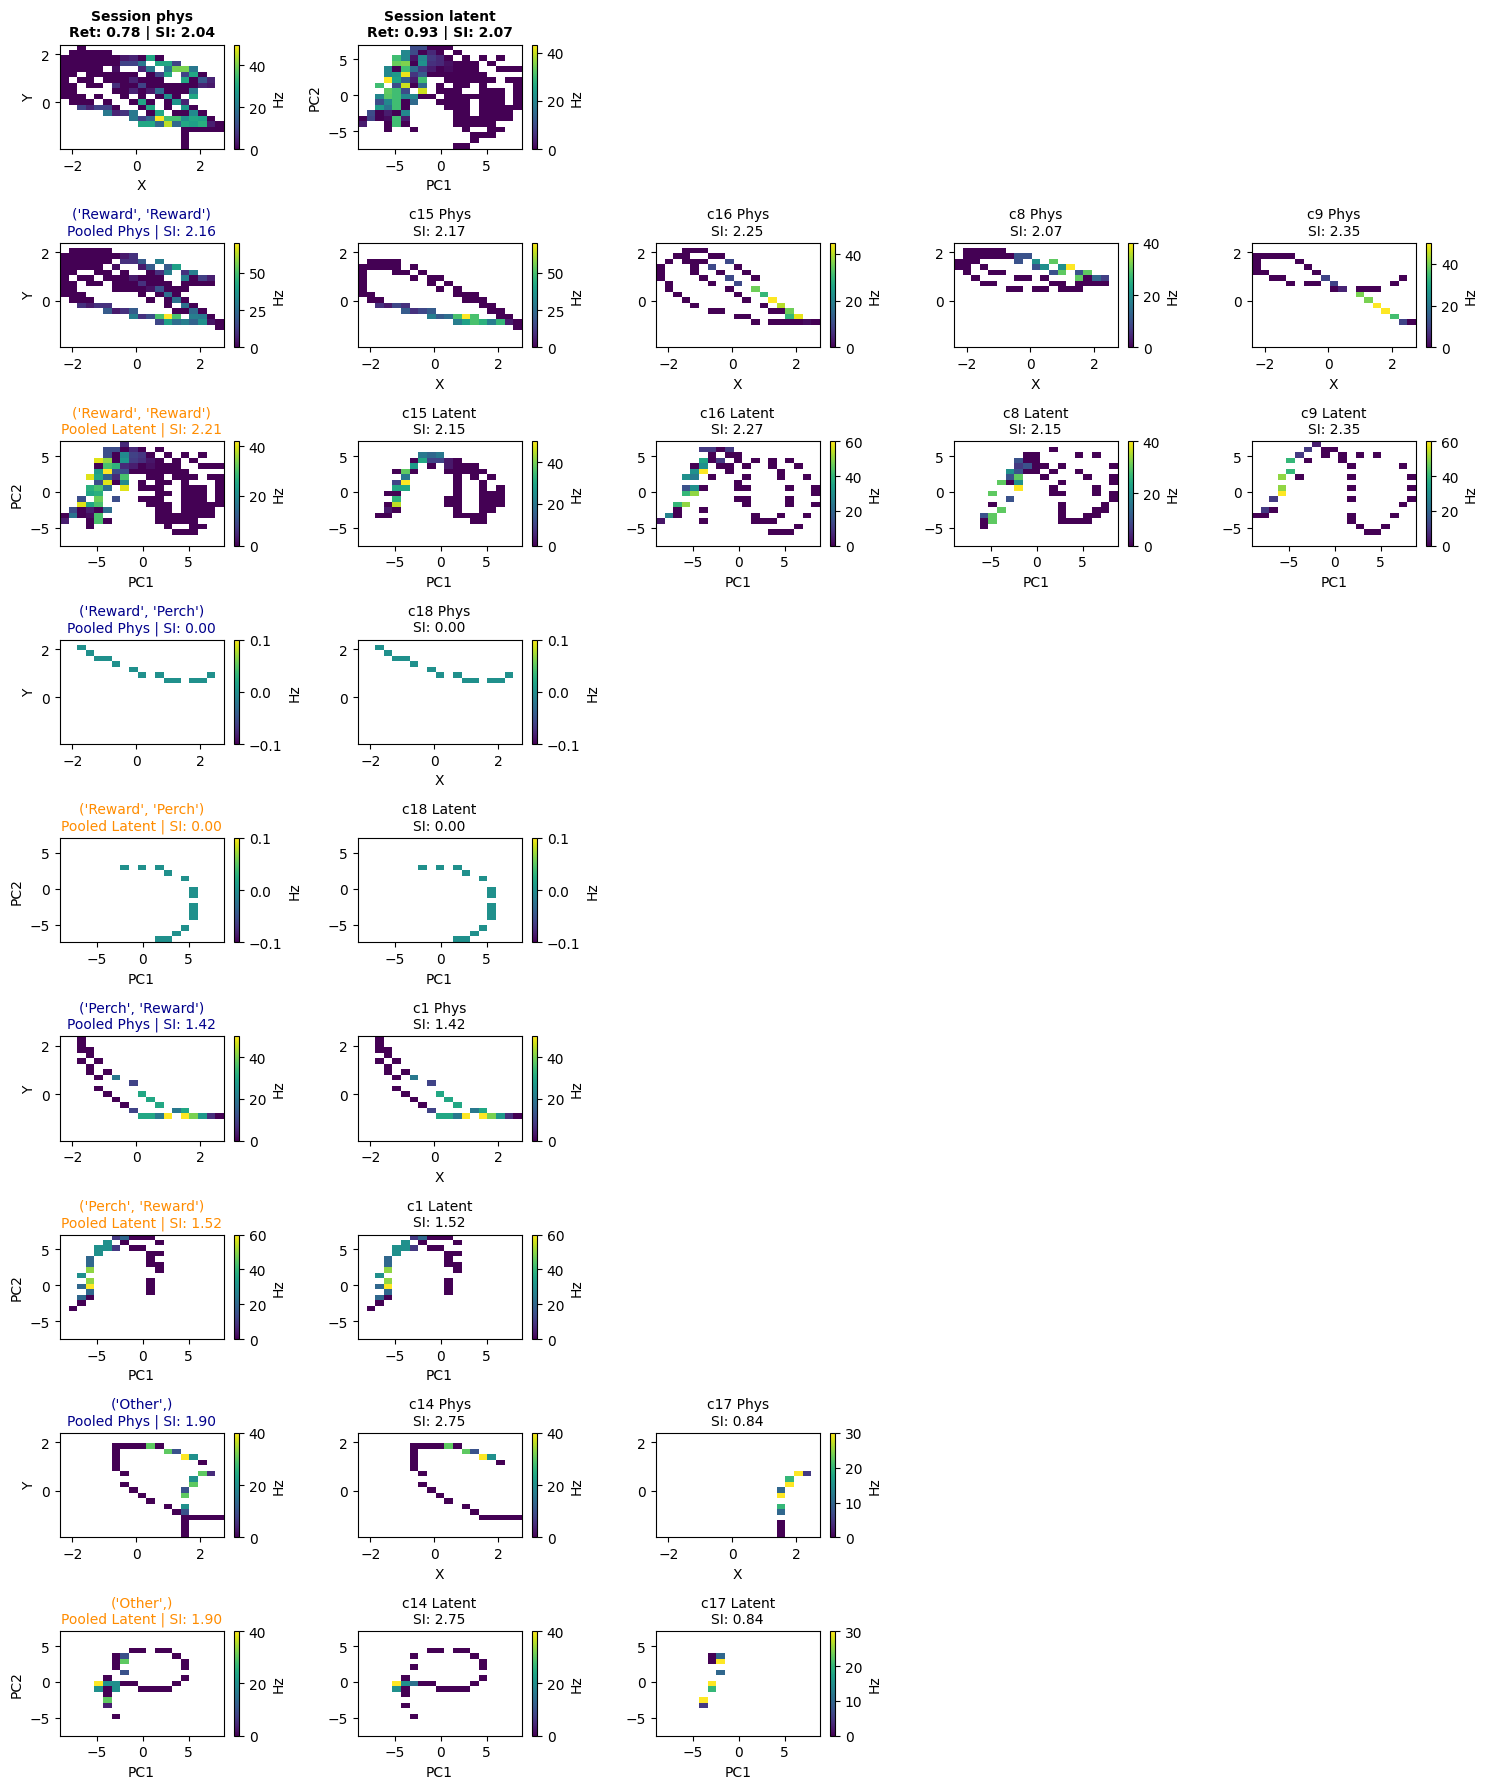

In [99]:
# Rate map for one example neuron in example session
min_si_threshold = 0.05 # ignore neurons with very low SI in the cluster (noise)
session_to_analyze = 'Dataset_1_32622_231009' # 'Dataset_1_32622_231009', 'Dataset_3_14543_240421'
analyzer = BatSpatialInfo(
    session_id=session_to_analyze,
    all_session=all_session,
    all_xyz=all_xyz,
    pca_sub=all_latents_pca3,
    all_latents=all_latents,
    all_true_spike=all_true_spike,
    all_cluster_session=all_cluster_session,
    all_rel_time=all_rel_time, 
    all_reward=all_reward, 
    all_perch=all_perch,
)
# 2. Run the computation
results = analyzer.get_all_spatial_info()
# 3. Extract session SI values
session_phys = results['session_si_physical']
session_latent = results['session_si_latent_3d']
# extract cluster SI values and get the maximum for each neuron
cluster_phys, cluster_latent = [], []
for clu, dic in results['clusters'].items():
    cluster_phys.append(dic['si_physical'])
    cluster_latent.append(dic['si_latent_3d'])
cluster_phys = np.array(cluster_phys)
cluster_latent = np.array(cluster_latent) # shape: (num_of_clusters, num_of_neurons)
cluster_phys = np.max(cluster_phys, axis=0)
cluster_latent = np.max(cluster_latent, axis=0)
# We only care about neurons that actually have a place field in this geometry
active_mask = (cluster_phys > min_si_threshold) | (cluster_latent > min_si_threshold)
active_indices = np.where(active_mask)[0]
c_phys = cluster_phys[active_mask]
c_lat = cluster_latent[active_mask]
g_phys = session_phys[active_mask]
g_lat = session_latent[active_mask]
# 3. Calculate Retention Index (session / Cluster)
# Adding a tiny epsilon to avoid division by zero
phys_invariance = g_phys / c_phys
lat_invariance = g_lat / c_lat


# plot
ret = 0.52
ind_active = 75 # 70 # 48 # 40 # abs(lat_invariance-ret).argmin()
ind = 13 # 13, 81, 69, 12 # active_indices[ind_active]
loc_xyz_lim = np.stack((np.min(analyzer.xyz, axis=0), np.max(analyzer.xyz, axis=0)), axis=0) # shape: (2, 3)
loc_pca_3d_lim = np.stack((np.min(analyzer.pca_3d, axis=0), np.max(analyzer.pca_3d, axis=0)), axis=0)
loc_bin_width = None
num_of_bins = 20
dt = 0.1
rate_map_nan = True # If True, keep NaN values in rate map indicating the place never been visited
colorbar_label = 'Hz'
print(f'Session: {session_to_analyze}; Neuron: {ind}')

# --- 1. Compute Max Columns Needed for Row Layouts ---
# Determine how many columns we need. Each functional block needs: 
# 1 (for the pooled functional map) + number of sub-clusters
max_cols = 2  # Global session row needs at least 2 columns
for ft, ft_dict in results['flight_function_types'].items():
    num_clusters_in_ft = len(ft_dict['clusters'])
    if num_clusters_in_ft > 0:
        max_cols = max(max_cols, 1 + num_clusters_in_ft)
# Calculate total rows: 1 (global session) + 2 rows per valid functional type
valid_ft_keys = [ft for ft in results['flight_function_types'].keys() if len(results['flight_function_types'][ft]['clusters']) > 0]
total_plot_rows = 1 + (2 * len(valid_ft_keys))
# --- 2. Initialize the Figure GridSpec ---
fig = plt.figure(figsize=(max_cols * 3, total_plot_rows * 2))
gs = gridspec.GridSpec(total_plot_rows, max_cols, figure=fig)
# ROW 1: GLOBAL SESSION MAPS
# Physical Global Session Map
ax_glob_phys = fig.add_subplot(gs[0, 0])
spike_glob = analyzer.spikes
coord_glob_phys = analyzer.xyz
x_edges, y_edges, rate_map, _ = generate_2d_rate_map(
    coord_glob_phys[:, 0], coord_glob_phys[:, 1], spike_glob[:, ind], 
    loc_xx_lim=loc_xyz_lim[:, 0], loc_yy_lim=loc_xyz_lim[:, 1], 
    loc_bin_width=loc_bin_width, num_of_bins=num_of_bins, dt=dt, rate_map_nan=rate_map_nan,
)
im = ax_glob_phys.imshow(rate_map.T, origin='lower', extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]], cmap='viridis', aspect='auto')
ax_glob_phys.set_xlabel('X')
ax_glob_phys.set_ylabel('Y')
ax_glob_phys.set_title(f"Session phys\nRet: {phys_invariance[ind_active]:.2f} | SI: {session_phys[ind]:.2f}", fontsize=10, fontweight='bold')
plt.colorbar(im, ax=ax_glob_phys, label=colorbar_label)
# Latent Global Session Map
ax_glob_lat = fig.add_subplot(gs[0, 1])
coord_glob_lat = analyzer.pca_3d
x_edges, y_edges, rate_map, _ = generate_2d_rate_map(
    coord_glob_lat[:, 0], coord_glob_lat[:, 1], spike_glob[:, ind], 
    loc_xx_lim=loc_pca_3d_lim[:, 0], loc_yy_lim=loc_pca_3d_lim[:, 1], 
    loc_bin_width=loc_bin_width, num_of_bins=num_of_bins, dt=dt, rate_map_nan=rate_map_nan,
)
im = ax_glob_lat.imshow(rate_map.T, origin='lower', extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]], cmap='viridis', aspect='auto')
ax_glob_lat.set_xlabel('PC1')
ax_glob_lat.set_ylabel('PC2')
ax_glob_lat.set_title(f"Session latent\nRet: {lat_invariance[ind_active]:.2f} | SI: {session_latent[ind]:.2f}", fontsize=10, fontweight='bold')
plt.colorbar(im, ax=ax_glob_lat, label=colorbar_label)
# SUBSEQUENT ROWS: FUNCTIONAL TYPES & CLUSTERS
current_row_idx = 1
for ft in valid_ft_keys:
    ft_dict = results['flight_function_types'][ft]
    clusters_in_ft = ft_dict['clusters']
    # STEP A: Compile Pooled Spikes/Coords for this Flight Function Type
    ft_str = str(ft)
    ft_mask = (analyzer.flight_types == ft_str)
    spike_ft = analyzer.spikes[ft_mask]
    coord_ft_phys = analyzer.xyz[ft_mask]
    coord_ft_lat = analyzer.pca_3d[ft_mask]
    # Compute base SI over this functional category slice
    # Use fallback zeros if the array window has zero mean firing
    ft_si_phys = analyzer.compute_skaggs_si(coord_ft_phys, spike_ft, )[ind] if np.mean(spike_ft[:, ind]) > 0 else 0.0
    ft_si_lat = analyzer.compute_skaggs_si(coord_ft_lat, spike_ft, )[ind] if np.mean(spike_ft[:, ind]) > 0 else 0.0
    # STEP B: Plot Physical Row for this Functional Type
    # Col 0: Pooled Functional Type Map
    ax_ft_phys = fig.add_subplot(gs[current_row_idx, 0])
    x_edges, y_edges, rate_map, _ = generate_2d_rate_map(
        coord_ft_phys[:, 0], coord_ft_phys[:, 1], spike_ft[:, ind], 
        loc_xx_lim=loc_xyz_lim[:, 0], loc_yy_lim=loc_xyz_lim[:, 1], 
        loc_bin_width=loc_bin_width, num_of_bins=num_of_bins, dt=dt, rate_map_nan=rate_map_nan,
    )
    im = ax_ft_phys.imshow(rate_map.T, origin='lower', extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]], cmap='viridis', aspect='auto')
    ax_ft_phys.set_ylabel('Y')
    ax_ft_phys.set_title(f"{ft}\nPooled Phys | SI: {ft_si_phys:.2f}", fontsize=10, color='darkblue')
    plt.colorbar(im, ax=ax_ft_phys, label=colorbar_label)
    # Cols 1+: Individual Clusters matching this Functional Type
    for c_idx, clu in enumerate(clusters_in_ft.keys()):
        cluster_data = clusters_in_ft[clu]
        ax_c_phys = fig.add_subplot(gs[current_row_idx, c_idx + 1])
        x_edges, y_edges, rate_map, _ = generate_2d_rate_map(
            cluster_data['xyz'][:, 0], cluster_data['xyz'][:, 1], cluster_data['spikes'][:, ind], 
            loc_xx_lim=loc_xyz_lim[:, 0], loc_yy_lim=loc_xyz_lim[:, 1], 
            loc_bin_width=loc_bin_width, num_of_bins=num_of_bins, dt=dt, rate_map_nan=rate_map_nan,
        )
        im = ax_c_phys.imshow(rate_map.T, origin='lower', extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]], cmap='viridis', aspect='auto')
        ax_c_phys.set_xlabel('X')
        ax_c_phys.set_title(f"{clu.split('_')[-1]} Phys\nSI: {cluster_data['si_physical'][ind]:.2f}", fontsize=10)
        plt.colorbar(im, ax=ax_c_phys, label=colorbar_label)
    # STEP C: Plot Latent Row for this Functional Type
    # Col 0: Pooled Functional Type Map
    current_row_idx += 1
    ax_ft_lat = fig.add_subplot(gs[current_row_idx, 0])
    x_edges, y_edges, rate_map, _ = generate_2d_rate_map(
        coord_ft_lat[:, 0], coord_ft_lat[:, 1], spike_ft[:, ind], 
        loc_xx_lim=loc_pca_3d_lim[:, 0], loc_yy_lim=loc_pca_3d_lim[:, 1], 
        loc_bin_width=loc_bin_width, num_of_bins=num_of_bins, dt=dt, rate_map_nan=rate_map_nan,
    )
    im = ax_ft_lat.imshow(rate_map.T, origin='lower', extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]], cmap='viridis', aspect='auto')
    ax_ft_lat.set_ylabel('PC2')
    ax_ft_lat.set_xlabel('PC1')
    ax_ft_lat.set_title(f"{ft}\nPooled Latent | SI: {ft_si_lat:.2f}", fontsize=10, color='darkorange')
    plt.colorbar(im, ax=ax_ft_lat, label=colorbar_label)
    # Cols 1+: Individual Clusters matching this Functional Type
    for c_idx, clu in enumerate(clusters_in_ft.keys()):
        cluster_data = clusters_in_ft[clu]
        ax_c_lat = fig.add_subplot(gs[current_row_idx, c_idx + 1])
        x_edges, y_edges, rate_map, _ = generate_2d_rate_map(
            cluster_data['pca_3d'][:, 0], cluster_data['pca_3d'][:, 1], cluster_data['spikes'][:, ind], 
            loc_xx_lim=loc_pca_3d_lim[:, 0], loc_yy_lim=loc_pca_3d_lim[:, 1], 
            loc_bin_width=loc_bin_width, num_of_bins=num_of_bins, dt=dt, rate_map_nan=rate_map_nan,
        )
        im = ax_c_lat.imshow(rate_map.T, origin='lower', extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]], cmap='viridis', aspect='auto')
        ax_c_lat.set_xlabel('PC1')
        ax_c_lat.set_title(f"{clu.split('_')[-1]} Latent\nSI: {cluster_data['si_latent_3d'][ind]:.2f}", fontsize=10)
        plt.colorbar(im, ax=ax_c_lat, label=colorbar_label)
    # Next row
    current_row_idx += 1
plt.tight_layout()

/mnt/scratch09/yongrong/projects/bat-intelligence/src/digitalbat/digitalbat/utility/utils.py:2222: RuntimeWarning: Mean of empty slice
  shuffled_results[space] = np.nanmean(np.array(shuffle_pairs), axis=0)


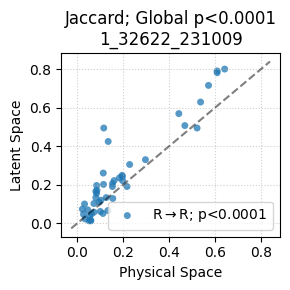

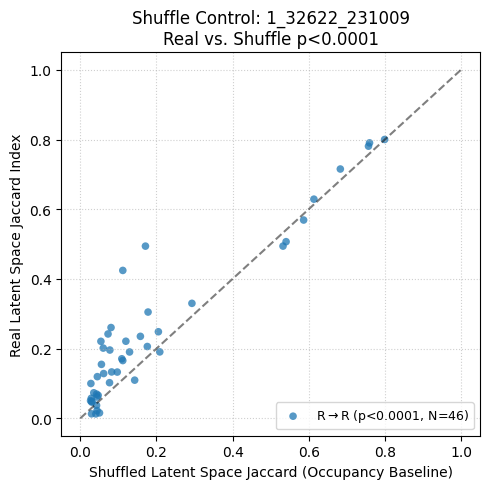

In [29]:
# jaccard; example + shuffle test
session_to_analyze = 'Dataset_1_32622_231009' # 'Dataset_1_32622_231009', 'Dataset_3_14543_240421'
analyzer = BatRateMapSim(
    session_id=session_to_analyze,
    all_session=all_session,
    all_xyz=all_xyz,
    pca_sub=all_latents_pca3,
    all_latents=all_latents,
    all_true_spike=all_true_spike,
    all_cluster_session=all_cluster_session,
    all_rel_time=all_rel_time, 
    all_reward=all_reward, 
    all_perch=all_perch,
)
spatial_jac = analyzer.get_all_Jaccard()

# 1. Define the targets and colors (excluding ('Other',))
target_types = [
    ('Reward', 'Reward'), 
    ('Reward', 'Perch'), 
    ('Perch', 'Reward'), 
    ('Perch', 'Perch')
]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'] # Distinct professional palette
fig, ax = plt.subplots(figsize=(3, 3))
# Track global arrays to perform an overall session-wide statistical test if needed
all_filtered_phys = []
all_filtered_lat = []
# 2. Loop over each flight functional type and plot
for ft, color in zip(target_types, colors):
    if ft not in spatial_jac['flight_function_types']:
        continue
    phys_data = spatial_jac['flight_function_types'][ft]['jaccard_physical']
    lat_data = spatial_jac['flight_function_types'][ft]['jaccard_latent']
    # Create a mask to exclude NaN values on a per-neuron basis
    valid_mask = ~np.isnan(phys_data) & ~np.isnan(lat_data)
    phys_filtered = phys_data[valid_mask]
    lat_filtered = lat_data[valid_mask]
    if len(phys_filtered) == 0:
        continue
    all_filtered_phys.extend(phys_filtered)
    all_filtered_lat.extend(lat_filtered)
    # Calculate p-value for this specific functional type
    # A minimum of 20 samples is typically preferred for stable Wilcoxon testing asymptotics
    if len(phys_filtered) >= 5:
        _, p_val = wilcoxon(lat_filtered, phys_filtered, alternative='two-sided')
        p_str = f"p={p_val:.4f}" if p_val >= 0.0001 else "p<0.0001"
    else:
        p_str = "N too small"
    # Plot the scatter points for this type
    label_text = f"{ft[0][0]}$\\rightarrow${ft[1][0]}; {p_str}"
    ax.scatter(phys_filtered, lat_filtered, color=color, alpha=0.75, edgecolors='none', s=25, label=label_text)

# 3. Calculate global session statistical markers
all_filtered_phys = np.array(all_filtered_phys)
all_filtered_lat = np.array(all_filtered_lat)
if len(all_filtered_phys) >= 5:
    _, global_p = wilcoxon(all_filtered_lat, all_filtered_phys, alternative='two-sided')
    global_p_str = f"Global p={global_p:.4f}" if global_p >= 0.0001 else "Global p<0.0001"
else:
    global_p_str = ""
# Draw a identity diagonal reference line (y = x)
min_val = min(ax.get_xlim()[0], ax.get_ylim()[0])
max_val = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5)
ax.set_xlabel('Physical Space',)
ax.set_ylabel('Latent Space',)
ax.set_title(f"Jaccard; {global_p_str}\n{session_to_analyze[8:]}", )
ax.legend(loc='lower right', frameon=True)
ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()


# shuffle
# --- 1. Compute Empirical Data and Shuffled Baseline ---
session_to_analyze = 'Dataset_1_32622_231009' # 'Dataset_1_32622_231009', 'Dataset_3_14543_240421'
analyzer = BatRateMapSim(
    session_id=session_to_analyze,
    all_session=all_session,
    all_xyz=all_xyz,
    pca_sub=all_latents_pca3,
    all_latents=all_latents,
    all_true_spike=all_true_spike,
    all_cluster_session=all_cluster_session,
    all_rel_time=all_rel_time, 
    all_reward=all_reward, 
    all_perch=all_perch,
)

# Get the empirical Jaccard dictionaries
spatial_jac = analyzer.get_all_Jaccard()

# Run the occupancy-preserving shuffle control across targets
# Structure returned: shuffle_baseline[space] = 1D array of length n_neurons
target_types = [('Reward', 'Reward'), ('Reward', 'Perch'), ('Perch', 'Reward'), ('Perch', 'Perch')]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

fig, ax = plt.subplots(figsize=(5, 5))

all_real_lat_pool = []
all_shuff_lat_pool = []

# --- 2. Loop over each Flight Type and Evaluate Against Control ---
for ft, color in zip(target_types, colors):
    if ft not in spatial_jac['flight_function_types']:
        continue
        
    # Extract empirical latent index per neuron
    real_lat_data = spatial_jac['flight_function_types'][ft]['jaccard_latent']
    
    # Run shuffle function for this specific flight type block
    # (Using 20 shuffles per neuron to establish a stable null distribution)
    # shuffle_dict = get_shuffled_jaccard_baseline(analyzer, ft_str=str(ft), n_shuffles=20)
    shuffle_dict = analyzer.get_shuffled_jaccard_baseline(ft_str=str(ft), n_shuffles=20)
    shuff_lat_data = shuffle_dict['latent']
    
    # Create mask to exclude NaN neurons (i.e., those that didn't spike)
    if len(shuff_lat_data) == 0:
        continue
    valid_mask = ~np.isnan(real_lat_data) & ~np.isnan(shuff_lat_data)
    
    real_lat_filtered = real_lat_data[valid_mask]
    shuff_lat_filtered = shuff_lat_data[valid_mask]
    
    if len(real_lat_filtered) == 0:
        continue
        
    all_real_lat_pool.extend(real_lat_filtered)
    all_shuff_lat_pool.extend(shuff_lat_filtered)
    
    # Compute statistical significance vs. its own behavioral occupancy baseline
    if len(real_lat_filtered) >= 5:
        _, p_val = wilcoxon(real_lat_filtered, shuff_lat_filtered, alternative='two-sided')
        p_str = f"p={p_val:.4f}" if p_val >= 0.0001 else "p<0.0001"
    else:
        p_str = "N too small"
        
    # Plot real vs shuffled values
    label_text = f"{ft[0][0]}$\\rightarrow${ft[1][0]} ({p_str}, N={len(real_lat_filtered)})"
    ax.scatter(shuff_lat_filtered, real_lat_filtered, color=color, alpha=0.75, edgecolors='none', s=30, label=label_text)

# --- 3. Compute Global Pool Statistics ---
all_real_lat_pool = np.array(all_real_lat_pool)
all_shuff_lat_pool = np.array(all_shuff_lat_pool)

if len(all_real_lat_pool) >= 5:
    _, global_p = wilcoxon(all_real_lat_pool, all_shuff_lat_pool, alternative='two-sided')
    global_p_str = f"Real vs. Shuffle p={global_p:.4f}" if global_p >= 0.0001 else "Real vs. Shuffle p<0.0001"
else:
    global_p_str = ""

# --- 4. Plot Aesthetics and Grid Guidelines ---
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
ax.set_xlim([-0.05, 1.05])
ax.set_ylim([-0.05, 1.05])
ax.set_xlabel('Shuffled Latent Space Jaccard (Occupancy Baseline)')
ax.set_ylabel('Real Latent Space Jaccard Index')
ax.set_title(f"Shuffle Control: {session_to_analyze[8:]}\n{global_p_str}")
ax.legend(loc='lower right', frameon=True, fontsize=9)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()

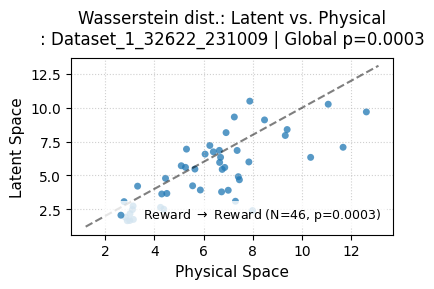

In [31]:
# %% Wasserstein example + shuffle test
session_to_analyze = 'Dataset_1_32622_231009' # 'Dataset_1_32622_231009', 'Dataset_3_14543_240421'
analyzer = BatRateMapSim(
    session_id=session_to_analyze,
    all_session=all_session,
    all_xyz=all_xyz,
    pca_sub=all_latents_pca3,
    all_latents=all_latents,
    all_true_spike=all_true_spike,
    all_cluster_session=all_cluster_session,
    all_rel_time=all_rel_time, 
    all_reward=all_reward, 
    all_perch=all_perch,
)
spatial_wass = analyzer.get_all_Wasserstein()

# 1. Define the targets and colors (excluding ('Other',))
target_types = [
    ('Reward', 'Reward'), 
    ('Reward', 'Perch'), 
    ('Perch', 'Reward'), 
    ('Perch', 'Perch')
]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'] # Distinct professional palette

fig, ax = plt.subplots(figsize=(4, 3))
# Track global arrays to perform an overall session-wide statistical test if needed
all_filtered_phys = []
all_filtered_lat = []
# 2. Loop over each flight functional type and plot
for ft, color in zip(target_types, colors):
    if ft not in spatial_wass['flight_function_types']:
        continue
    phys_data = spatial_wass['flight_function_types'][ft]['wass_physical']
    lat_data = spatial_wass['flight_function_types'][ft]['wass_latent']
    # Create a mask to exclude NaN values on a per-neuron basis
    valid_mask = ~np.isnan(phys_data) & ~np.isnan(lat_data)
    phys_filtered = phys_data[valid_mask]
    lat_filtered = lat_data[valid_mask]
    if len(phys_filtered) == 0:
        continue

    all_filtered_phys.extend(phys_filtered)
    all_filtered_lat.extend(lat_filtered)
    # Calculate p-value for this specific functional type
    # A minimum of 20 samples is typically preferred for stable Wilcoxon testing asymptotics
    if len(phys_filtered) >= 5:
        _, p_val = wilcoxon(lat_filtered, phys_filtered, alternative='two-sided')
        p_str = f"p={p_val:.4f}" if p_val >= 0.0001 else "p<0.0001"
    else:
        p_str = "N too small"
    # Plot the scatter points for this type
    label_text = f"{ft[0]} $\\rightarrow$ {ft[1]} (N={len(phys_filtered)}, {p_str})"
    ax.scatter(phys_filtered, lat_filtered, color=color, alpha=0.75, edgecolors='none', s=25, label=label_text)

# 3. Calculate global session statistical markers
all_filtered_phys = np.array(all_filtered_phys)
all_filtered_lat = np.array(all_filtered_lat)
if len(all_filtered_phys) >= 5:
    _, global_p = wilcoxon(all_filtered_lat, all_filtered_phys, alternative='two-sided')
    global_p_str = f"Global p={global_p:.4f}" if global_p >= 0.0001 else "Global p<0.0001"
else:
    global_p_str = ""

# 4. Refine Figure Aesthetics and Guidelines
# Draw a identity diagonal reference line (y = x)
min_val = min(ax.get_xlim()[0], ax.get_ylim()[0])
max_val = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5)
# ax.set_xlim([min_val, 1.05])
# ax.set_ylim([min_val, 1.05])
ax.set_xlabel('Physical Space', fontsize=11)
ax.set_ylabel('Latent Space', fontsize=11)
ax.set_title(f"Wasserstein dist.: Latent vs. Physical\n: {session_to_analyze} | {global_p_str}", 
             fontsize=12, pad=10)

ax.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='none', fontsize=9)
ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()


# # shuffle
# # --- 1. Compute Empirical Data and Shuffled Baseline ---
# session_to_analyze = 'Dataset_1_32622_231009' # 'Dataset_1_32622_231009', 'Dataset_3_14543_240421'
# analyzer = BatRateMapSim(
#     session_id=session_to_analyze,
#     all_session=all_session,
#     all_xyz=all_xyz,
#     pca_sub=all_latents_pca3,
#     all_latents=all_latents,
#     all_true_spike=all_true_spike,
#     all_cluster_session=all_cluster_session,
#     all_rel_time=all_rel_time, 
#     all_reward=all_reward, 
#     all_perch=all_perch,
# )

# # Get the empirical Jaccard dictionaries
# spatial_wass = analyzer.get_all_Wasserstein()

# # Run the occupancy-preserving shuffle control across targets
# # Structure returned: shuffle_baseline[space] = 1D array of length n_neurons
# target_types = [('Reward', 'Reward'), ('Reward', 'Perch'), ('Perch', 'Reward'), ('Perch', 'Perch')]
# colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

# fig, ax = plt.subplots(figsize=(5, 5))

# all_real_lat_pool = []
# all_shuff_lat_pool = []

# # --- 2. Loop over each Flight Type and Evaluate Against Control ---
# for ft, color in zip(target_types, colors):
#     if ft not in spatial_wass['flight_function_types']:
#         continue
        
#     # Extract empirical latent index per neuron
#     real_lat_data = spatial_wass['flight_function_types'][ft]['wass_latent']
    
#     # Run shuffle function for this specific flight type block
#     # (Using 20 shuffles per neuron to establish a stable null distribution)
#     # shuffle_dict = get_shuffled_jaccard_baseline(analyzer, ft_str=str(ft), n_shuffles=20)
#     shuffle_dict = analyzer.get_shuffled_wass_baseline(ft_str=str(ft), n_shuffles=20)
#     shuff_lat_data = shuffle_dict['latent']
    
#     # Create mask to exclude NaN neurons (i.e., those that didn't spike)
#     if len(shuff_lat_data) == 0:
#         continue
#     valid_mask = ~np.isnan(real_lat_data) & ~np.isnan(shuff_lat_data)
    
#     real_lat_filtered = real_lat_data[valid_mask]
#     shuff_lat_filtered = shuff_lat_data[valid_mask]
    
#     if len(real_lat_filtered) == 0:
#         continue
        
#     all_real_lat_pool.extend(real_lat_filtered)
#     all_shuff_lat_pool.extend(shuff_lat_filtered)
    
#     # Compute statistical significance vs. its own behavioral occupancy baseline
#     if len(real_lat_filtered) >= 5:
#         _, p_val = wilcoxon(real_lat_filtered, shuff_lat_filtered, alternative='two-sided')
#         p_str = f"p={p_val:.4f}" if p_val >= 0.0001 else "p<0.0001"
#     else:
#         p_str = "N too small"
        
#     # Plot real vs shuffled values
#     label_text = f"{ft[0][0]}$\\rightarrow${ft[1][0]} ({p_str}, N={len(real_lat_filtered)})"
#     ax.scatter(shuff_lat_filtered, real_lat_filtered, color=color, alpha=0.75, edgecolors='none', s=30, label=label_text)

# # --- 3. Compute Global Pool Statistics ---
# all_real_lat_pool = np.array(all_real_lat_pool)
# all_shuff_lat_pool = np.array(all_shuff_lat_pool)

# if len(all_real_lat_pool) >= 5:
#     _, global_p = wilcoxon(all_real_lat_pool, all_shuff_lat_pool, alternative='two-sided')
#     global_p_str = f"Real vs. Shuffle p={global_p:.4f}" if global_p >= 0.0001 else "Real vs. Shuffle p<0.0001"
# else:
#     global_p_str = ""

# # --- 4. Plot Aesthetics and Grid Guidelines ---
# min_val = min(ax.get_xlim()[0], ax.get_ylim()[0])
# max_val = max(ax.get_xlim()[1], ax.get_ylim()[1])
# ax.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5)
# ax.set_xlabel('Shuffled Latent Space Wass Dist (Occupancy Baseline)')
# ax.set_ylabel('Real Latent Space Wass Dist')
# ax.set_title(f"Shuffle Control: {session_to_analyze[8:]}\n{global_p_str}")
# ax.legend(loc='lower right', frameon=True, fontsize=9)
# ax.grid(True, linestyle=':', alpha=0.6)

# plt.tight_layout()

## Across sessions, separate computation and plot

### Jaccard

In [12]:
# session_names = list(dataloaders['test'].keys())
# # 1. Define the targets and colors (excluding ('Other',))
# target_types = [
#     ('Reward', 'Reward'), 
#     ('Reward', 'Perch'), 
#     ('Perch', 'Reward'), 
#     ('Perch', 'Perch')
# ]
# colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'] # Distinct professional palette

# # --- 2. Extract and Group Data Across All Sessions ---
# spatial_sessions = {}
# shuffle_sessions = {}
# for session_to_analyze in session_names:
#     print(session_to_analyze)
#     # compute empirical index
#     analyzer = BatRateMapSim(
#         session_id=session_to_analyze,
#         all_session=all_session,
#         all_xyz=all_xyz,
#         pca_sub=all_latents_pca3,
#         all_latents=all_latents,
#         all_true_spike=all_true_spike,
#         all_cluster_session=all_cluster_session,
#         all_rel_time=all_rel_time, 
#         all_reward=all_reward, 
#         all_perch=all_perch,
#     )
#     spatial = analyzer.get_all_Jaccard()
#     spatial_sessions[session_to_analyze] = spatial
#     # shuffle
#     shuffle = {'flight_function_types': {}}
#     for ft, color in zip(target_types, colors):
#         if ft not in spatial['flight_function_types']:
#             continue
#         # Run shuffle function for this specific flight type block
#         # (Using 20 shuffles per neuron to establish a stable null distribution)
#         # shuffle_dict = get_shuffled_jaccard_baseline(analyzer, ft_str=str(ft), n_shuffles=20)
#         shuffle_dict = analyzer.get_shuffled_jaccard_baseline(ft_str=str(ft), n_shuffles=20)
#         shuffle['flight_function_types'][ft] = shuffle_dict
#     shuffle_sessions[session_to_analyze] = shuffle

# # save
# with open('./out/spatial_jaccard.pkl', 'wb') as ff:
#     pickle.dump(spatial_sessions, ff)
# with open('./out/spatial_jaccard_shuffle.pkl', 'wb') as ff:
#     pickle.dump(shuffle_sessions, ff)    

In [13]:
with open('./out/spatial_jaccard.pkl', 'rb') as ff:
    spatial_sessions = pickle.load(ff)
with open('./out/spatial_jaccard_shuffle.pkl', 'rb') as ff:
    shuffle_sessions = pickle.load(ff)

/tmp/ipykernel_10485/1569868537.py:63: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[ii,jj].legend(loc='lower right', frameon=True)


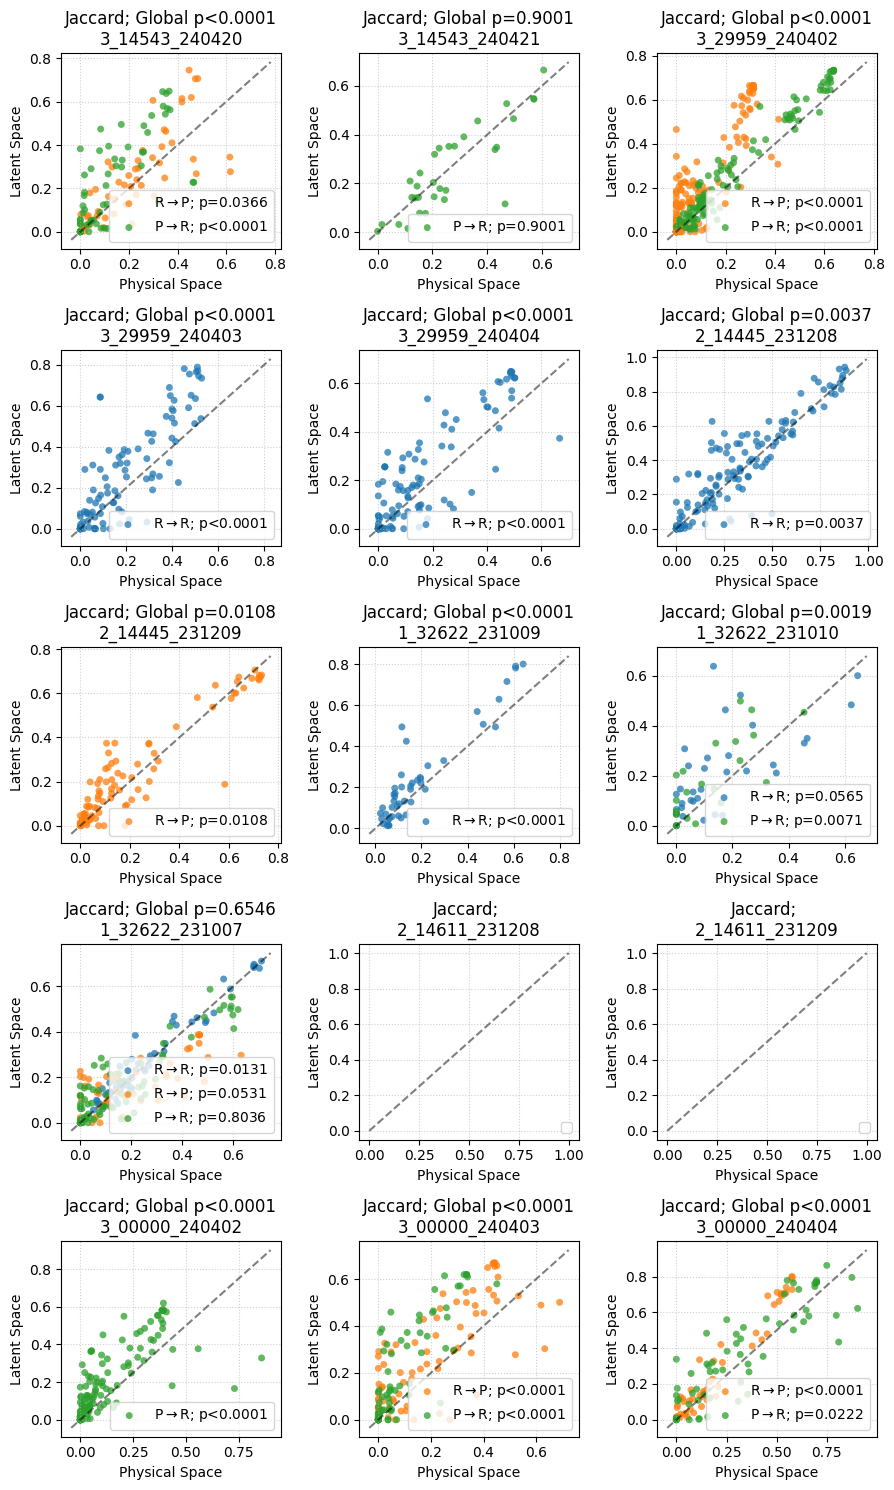

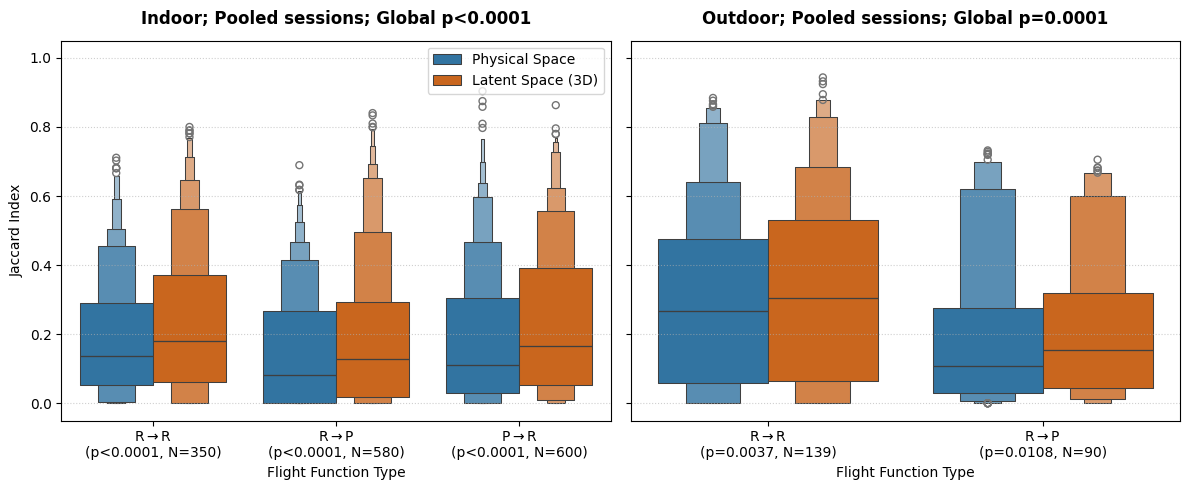

In [14]:
# jaccard for all sessions
session_names = list(dataloaders['test'].keys())
ncols = 3 
nrows = len(session_names) // ncols
# 1. Define the targets and colors (excluding ('Other',))
target_types = [
    ('Reward', 'Reward'), 
    ('Reward', 'Perch'), 
    ('Perch', 'Reward'), 
    ('Perch', 'Perch')
]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'] # Distinct professional palette
fig, axes = plt.subplots(nrows=nrows, ncols=ncols,figsize=(ncols*3,nrows*3))
for ii in range(nrows):
    for jj in range(ncols):
        session_to_analyze = list(dataloaders['test'].keys()) [ii * ncols + jj]
        spatial_jac = spatial_sessions[session_to_analyze]
        
        # Track global arrays to perform an overall session-wide statistical test if needed
        all_filtered_phys = []
        all_filtered_lat = []
        # 2. Loop over each flight functional type and plot
        for ft, color in zip(target_types, colors):
            if ft not in spatial_jac['flight_function_types']:
                continue
            phys_data = spatial_jac['flight_function_types'][ft]['jaccard_physical']
            lat_data = spatial_jac['flight_function_types'][ft]['jaccard_latent']
            # Create a mask to exclude NaN values on a per-neuron basis
            valid_mask = ~np.isnan(phys_data) & ~np.isnan(lat_data)
            phys_filtered = phys_data[valid_mask]
            lat_filtered = lat_data[valid_mask]
            if len(phys_filtered) == 0:
                continue
            all_filtered_phys.extend(phys_filtered)
            all_filtered_lat.extend(lat_filtered)
            # Calculate p-value for this specific functional type
            # A minimum of 20 samples is typically preferred for stable Wilcoxon testing asymptotics
            if len(phys_filtered) >= 5:
                _, p_val = wilcoxon(lat_filtered, phys_filtered, alternative='two-sided')
                p_str = f"p={p_val:.4f}" if p_val >= 0.0001 else "p<0.0001"
            else:
                p_str = "N too small"
            # Plot the scatter points for this type
            label_text = f"{ft[0][0]}$\\rightarrow${ft[1][0]}; {p_str}"
            axes[ii,jj].scatter(phys_filtered, lat_filtered, color=color, alpha=0.75, edgecolors='none', 
                s=25, label=label_text)

        # 3. Calculate global session statistical markers
        all_filtered_phys = np.array(all_filtered_phys)
        all_filtered_lat = np.array(all_filtered_lat)
        if len(all_filtered_phys) >= 5:
            _, global_p = wilcoxon(all_filtered_lat, all_filtered_phys, alternative='two-sided')
            global_p_str = f"Global p={global_p:.4f}" if global_p >= 0.0001 else "Global p<0.0001"
        else:
            global_p_str = ""
        # Draw a identity diagonal reference line (y = x)
        min_val = min(axes[ii,jj].get_xlim()[0], axes[ii,jj].get_ylim()[0])
        max_val = max(axes[ii,jj].get_xlim()[1], axes[ii,jj].get_ylim()[1])
        axes[ii,jj].plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5)
        axes[ii,jj].set_xlabel('Physical Space',)
        axes[ii,jj].set_ylabel('Latent Space',)
        axes[ii,jj].set_title(f"Jaccard; {global_p_str}\n{session_to_analyze[8:]}", )
        axes[ii,jj].legend(loc='lower right', frameon=True)
        axes[ii,jj].grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()


# jaccard: indoor vs. outdoor
# --- 1. Data Collection Initialization ---
target_types = [
    ('Reward', 'Reward'), 
    ('Reward', 'Perch'), 
    ('Perch', 'Reward'), 
    ('Perch', 'Perch')
]
session_names = list(dataloaders['test'].keys())

# Tracking framework separated by environment condition
# Structure: env_aggregation[env_key][ft] = {'phys': [], 'lat': []}
env_aggregation = {
    'Indoor':  {ft: {'phys': [], 'lat': []} for ft in target_types},
    'Outdoor': {ft: {'phys': [], 'lat': []} for ft in target_types}
}

# --- 2. Extract and Group Data Across All Sessions ---
for session_to_analyze in session_names:
    # Classify session environment
    if 'Dataset_1' in session_to_analyze or 'Dataset_3' in session_to_analyze:
        env_key = 'Indoor'
    elif 'Dataset_2' in session_to_analyze:
        env_key = 'Outdoor'
    else:
        continue  # Skip unclassified sessions
        
    spatial_jac = spatial_sessions[session_to_analyze]
    
    for ft in target_types:
        if ft not in spatial_jac['flight_function_types']:
            continue
            
        phys_data = spatial_jac['flight_function_types'][ft]['jaccard_physical']
        lat_data = spatial_jac['flight_function_types'][ft]['jaccard_latent']
        
        # Clean out NaNs for paired evaluations
        valid_mask = ~np.isnan(phys_data) & ~np.isnan(lat_data)
        phys_filtered = phys_data[valid_mask]
        lat_filtered = lat_data[valid_mask]
        
        if len(phys_filtered) == 0:
            continue
            
        env_aggregation[env_key][ft]['phys'].extend(phys_filtered)
        env_aggregation[env_key][ft]['lat'].extend(lat_filtered)

# --- 3. Construct DataFrames and Plot ---
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5), sharey=True)
env_keys = ['Indoor', 'Outdoor']
palette_dict = {'Physical Space': '#1f77b4', 'Latent Space (3D)': '#e66101'}

for idx, env in enumerate(env_keys):
    ax = axes[idx]
    records = []
    all_env_phys = []
    all_env_lat = []
    
    # Process each flight function type within this environment
    for ft in target_types:
        phys_arr = np.array(env_aggregation[env][ft]['phys'])
        lat_arr = np.array(env_aggregation[env][ft]['lat'])
        n_samples = len(phys_arr)
        
        if n_samples == 0:
            continue
            
        all_env_phys.extend(phys_arr)
        all_env_lat.extend(lat_arr)
        
        # Compute category specific significance
        if n_samples >= 5:
            _, p_val = wilcoxon(lat_arr, phys_arr, alternative='two-sided')
            p_str = f"p={p_val:.4f}" if p_val >= 0.0001 else "p<0.0001"
        else:
            p_str = "N too small"
            
        # Format the x-axis tick text with statistics
        label_string = f"{ft[0][0]}$\\rightarrow${ft[1][0]}\n({p_str}, N={n_samples})"
        
        for p_val_item in phys_arr:
            records.append({'Category': label_string, 'Jaccard Index': p_val_item, 'Space': 'Physical Space'})
        for l_val_item in lat_arr:
            records.append({'Category': label_string, 'Jaccard Index': l_val_item, 'Space': 'Latent Space (3D)'})
            
    if len(records) == 0:
        ax.set_title(f"{env} (No Data Available)")
        continue
        
    df_env_plot = pd.DataFrame(records)
    
    # Compute environment global pool significance score
    all_env_phys = np.array(all_env_phys)
    all_env_lat = np.array(all_env_lat)
    _, env_global_p = wilcoxon(all_env_lat, all_env_phys, alternative='two-sided')
    env_global_p_str = f"Global p={env_global_p:.4f}" if env_global_p >= 0.0001 else "Global p<0.0001"
    
    # Draw the boxen plot for this environment
    sns.boxenplot(
        data=df_env_plot, 
        x='Category', 
        y='Jaccard Index', 
        hue='Space',
        palette=palette_dict,
        outlier_prop=0.05,
        ax=ax
    )
    
    # Formatting details per subplot
    ax.set_title(f"{env}; Pooled sessions; {env_global_p_str}", 
                 fontsize=12, fontweight='bold', pad=12)
    ax.set_xlabel('Flight Function Type')
    ax.grid(axis='y', linestyle=':', alpha=0.6)
    ax.set_ylim([-0.05, 1.05])
    
    # Clean up secondary labels to maintain clean alignment
    if idx == 0:
        ax.set_ylabel('Jaccard Index')
        ax.legend(loc='upper right', frameon=True)
    else:
        ax.set_ylabel('')
        ax.get_legend().remove() # Use master legend present on first subplot axis

plt.tight_layout()

/tmp/ipykernel_10485/1144877220.py:70: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[ii,jj].legend(loc='lower right', frameon=True)


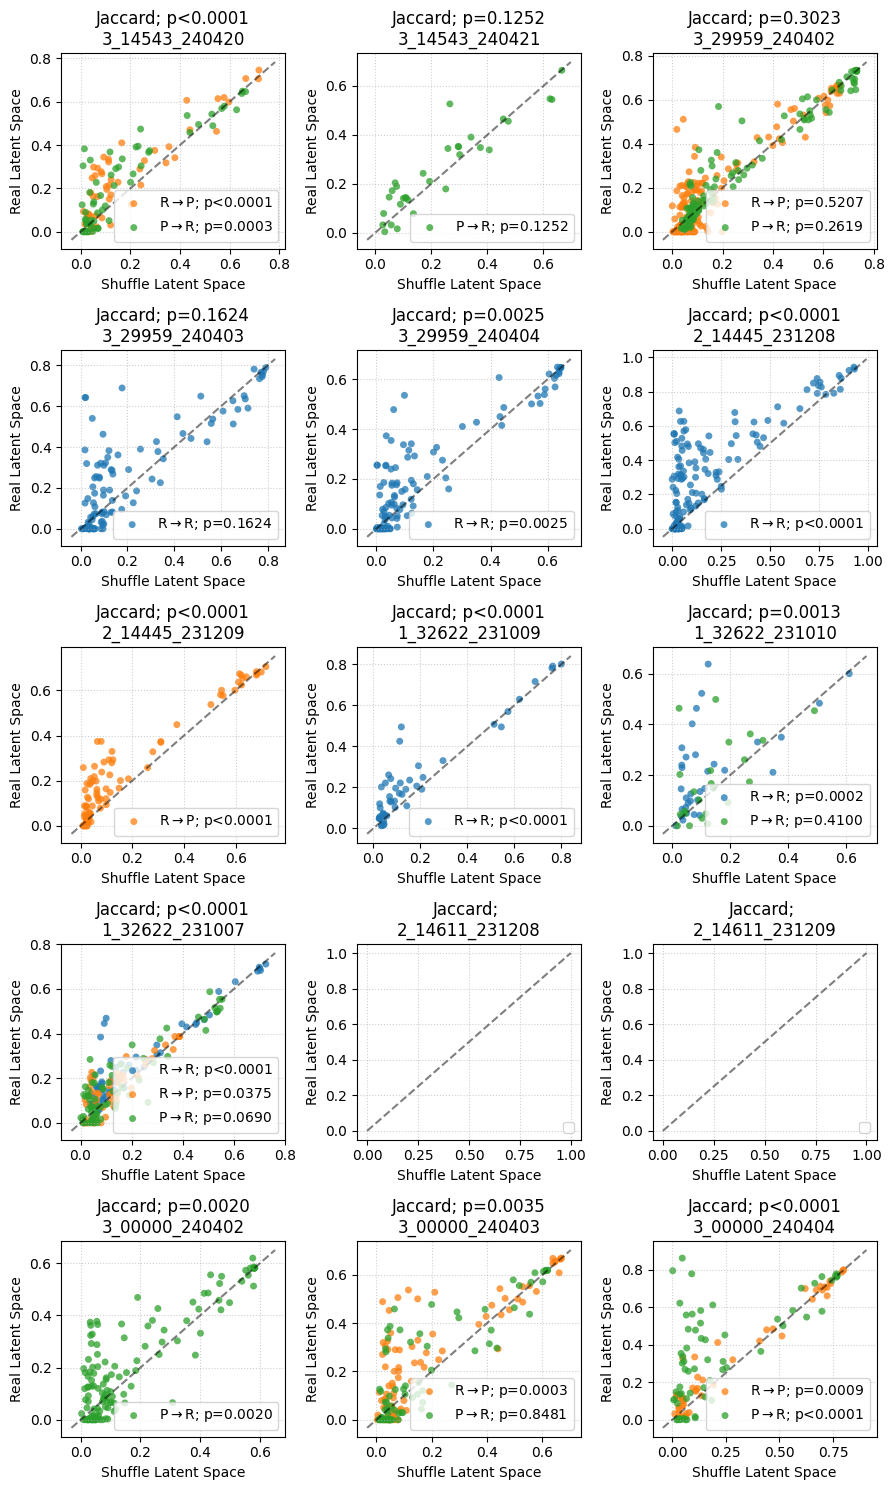

In [15]:
# Jaccard: shuffle test,  all sessions
session_names = list(dataloaders['test'].keys())
ncols = 3 
nrows = len(session_names) // ncols
# 1. Define the targets and colors (excluding ('Other',))
target_types = [
    ('Reward', 'Reward'), 
    ('Reward', 'Perch'), 
    ('Perch', 'Reward'), 
    ('Perch', 'Perch')
]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'] # Distinct professional palette
fig, axes = plt.subplots(nrows=nrows, ncols=ncols,figsize=(ncols*3,nrows*3))
for ii in range(nrows):
    for jj in range(ncols):
        session_to_analyze = list(dataloaders['test'].keys()) [ii * ncols + jj]
        # Get the empirical Jaccard dictionaries
        spatial_jac = spatial_sessions[session_to_analyze]
        all_real_lat_pool = []
        all_shuff_lat_pool = []
        # --- 2. Loop over each Flight Type and Evaluate Against Control ---
        for ft, color in zip(target_types, colors):
            if ft not in spatial_jac['flight_function_types']:
                continue
            # Extract empirical latent index per neuron
            real_lat_data = spatial_jac['flight_function_types'][ft]['jaccard_latent']
            # Run shuffle function for this specific flight type block
            # (Using 20 shuffles per neuron to establish a stable null distribution)
            # shuffle_dict = get_shuffled_jaccard_baseline(analyzer, ft_str=str(ft), n_shuffles=20)
            shuffle_dict = shuffle_sessions[session_to_analyze]['flight_function_types'][ft] # analyzer.get_shuffled_jaccard_baseline(ft_str=str(ft), n_shuffles=20)
            shuff_lat_data = shuffle_dict['latent']
            # Create mask to exclude NaN neurons (i.e., those that didn't spike)
            if len(shuff_lat_data) == 0:
                continue
            valid_mask = ~np.isnan(real_lat_data) & ~np.isnan(shuff_lat_data)
            
            real_lat_filtered = real_lat_data[valid_mask]
            shuff_lat_filtered = shuff_lat_data[valid_mask]
            if len(real_lat_filtered) == 0:
                continue
            all_real_lat_pool.extend(real_lat_filtered)
            all_shuff_lat_pool.extend(shuff_lat_filtered)
            
            # Compute statistical significance vs. its own behavioral occupancy baseline
            if len(real_lat_filtered) >= 5:
                _, p_val = wilcoxon(real_lat_filtered, shuff_lat_filtered, alternative='two-sided')
                p_str = f"p={p_val:.4f}" if p_val >= 0.0001 else "p<0.0001"
            else:
                p_str = "N too small"
                
            # Plot real vs shuffled values
            label_text = f"{ft[0][0]}$\\rightarrow${ft[1][0]}; {p_str}"
            axes[ii,jj].scatter(shuff_lat_filtered, real_lat_filtered, color=color, alpha=0.75, edgecolors='none', s=25, label=label_text)
        # --- 3. Compute Global Pool Statistics ---
        all_real_lat_pool = np.array(all_real_lat_pool)
        all_shuff_lat_pool = np.array(all_shuff_lat_pool)
        if len(all_real_lat_pool) >= 5:
            _, global_p = wilcoxon(all_real_lat_pool, all_shuff_lat_pool, alternative='two-sided')
            global_p_str = f"p={global_p:.4f}" if global_p >= 0.0001 else "p<0.0001"
        else:
            global_p_str = ""

        # Draw a identity diagonal reference line (y = x)
        min_val = min(axes[ii,jj].get_xlim()[0], axes[ii,jj].get_ylim()[0])
        max_val = max(axes[ii,jj].get_xlim()[1], axes[ii,jj].get_ylim()[1])
        axes[ii,jj].plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5)
        axes[ii,jj].set_xlabel('Shuffle Latent Space',)
        axes[ii,jj].set_ylabel('Real Latent Space',)
        axes[ii,jj].set_title(f"Jaccard; {global_p_str}\n{session_to_analyze[8:]}", )
        axes[ii,jj].legend(loc='lower right', frameon=True)
        axes[ii,jj].grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

### Wasserstein

In [16]:
# # this block of code may take several days
# session_names = list(dataloaders['test'].keys())
# # 1. Define the targets and colors (excluding ('Other',))
# target_types = [
#     ('Reward', 'Reward'), 
#     ('Reward', 'Perch'), 
#     ('Perch', 'Reward'), 
#     ('Perch', 'Perch')
# ]
# colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'] # Distinct professional palette

# # --- 2. Extract and Group Data Across All Sessions ---
# spatial_sessions = {}
# shuffle_sessions = {}
# for session_to_analyze in session_names:
#     print(session_to_analyze)
#     # compute empirical index
#     analyzer = BatRateMapSim(
#         session_id=session_to_analyze,
#         all_session=all_session,
#         all_xyz=all_xyz,
#         pca_sub=all_latents_pca3,
#         all_latents=all_latents,
#         all_true_spike=all_true_spike,
#         all_cluster_session=all_cluster_session,
#         all_rel_time=all_rel_time, 
#         all_reward=all_reward, 
#         all_perch=all_perch,
#     )
#     spatial = analyzer.get_all_Wasserstein()
#     spatial_sessions[session_to_analyze] = spatial
#     # shuffle
#     shuffle = {'flight_function_types': {}}
#     for ft, color in zip(target_types, colors):
#         if ft not in spatial['flight_function_types']:
#             continue
#         # Run shuffle function for this specific flight type block
#         # (Using 20 shuffles per neuron to establish a stable null distribution)
#         # shuffle_dict = get_shuffled_jaccard_baseline(analyzer, ft_str=str(ft), n_shuffles=20)
#         shuffle_dict = analyzer.get_shuffled_wass_baseline(ft_str=str(ft), n_shuffles=20)
#         shuffle['flight_function_types'][ft] = shuffle_dict
#     shuffle_sessions[session_to_analyze] = shuffle

# # save 
# with open('./out/spatial_wasserstein.pkl', 'wb') as ff:
#     pickle.dump(spatial_sessions, ff)
# with open('./out/spatial_wasserstein_shuffle.pkl', 'wb') as ff:
#     pickle.dump(shuffle_sessions, ff)    

In [17]:
with open('./out/spatial_wasserstein.pkl', 'rb') as ff:
    spatial_sessions = pickle.load(ff)
with open('./out/spatial_wasserstein_shuffle.pkl', 'rb') as ff:
    shuffle_sessions = pickle.load(ff)

/tmp/ipykernel_10485/3481478371.py:63: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[ii,jj].legend(loc='lower right', frameon=True)


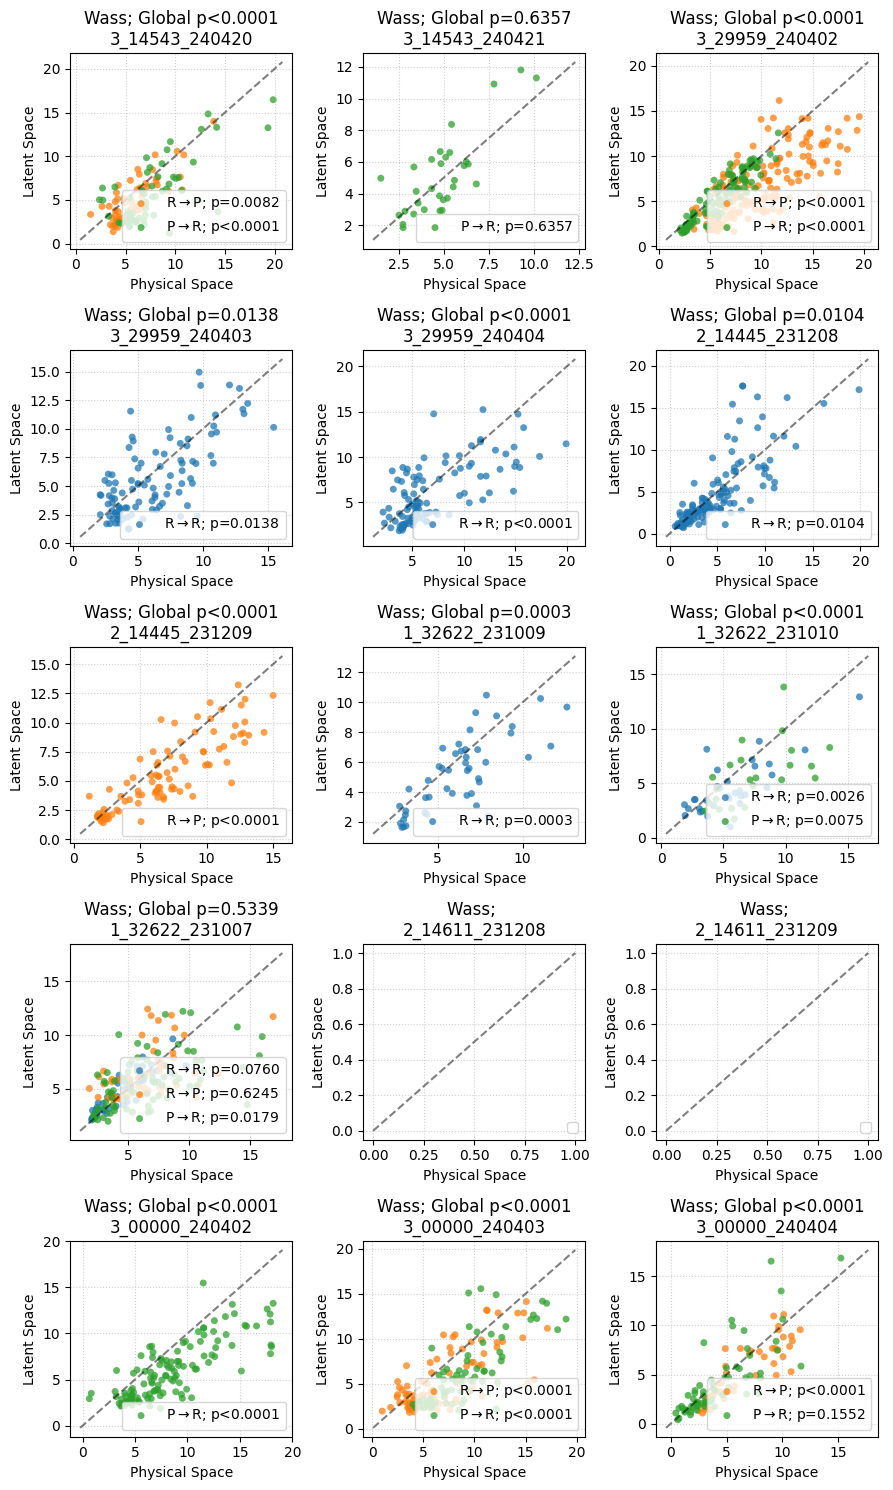

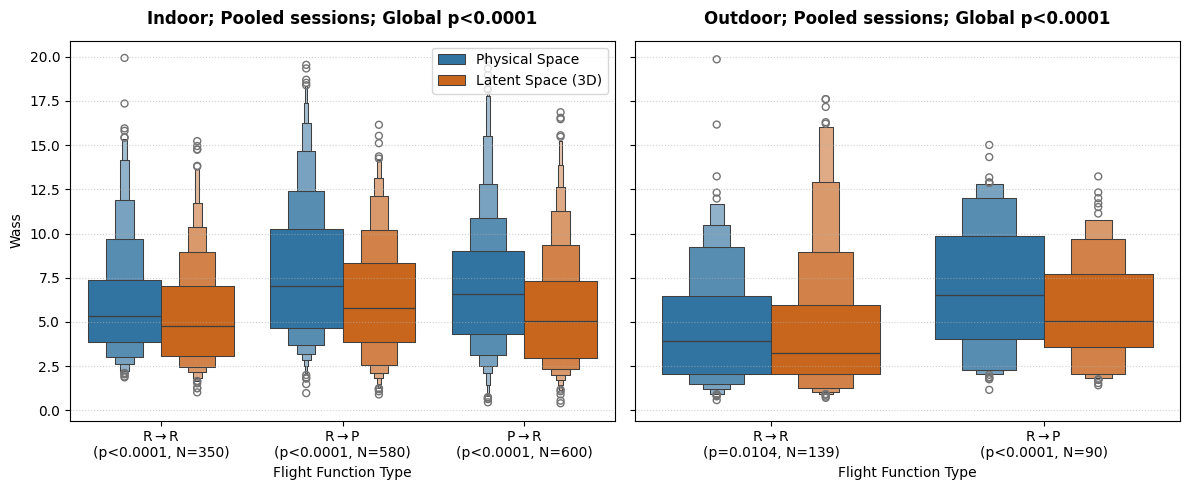

In [18]:
# Wass for all sessions
session_names = list(dataloaders['test'].keys())
ncols = 3 
nrows = len(session_names) // ncols
# 1. Define the targets and colors (excluding ('Other',))
target_types = [
    ('Reward', 'Reward'), 
    ('Reward', 'Perch'), 
    ('Perch', 'Reward'), 
    ('Perch', 'Perch')
]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'] # Distinct professional palette
fig, axes = plt.subplots(nrows=nrows, ncols=ncols,figsize=(ncols*3,nrows*3))
for ii in range(nrows):
    for jj in range(ncols):
        session_to_analyze = list(dataloaders['test'].keys()) [ii * ncols + jj]
        spatial_jac = spatial_sessions[session_to_analyze]
        
        # Track global arrays to perform an overall session-wide statistical test if needed
        all_filtered_phys = []
        all_filtered_lat = []
        # 2. Loop over each flight functional type and plot
        for ft, color in zip(target_types, colors):
            if ft not in spatial_jac['flight_function_types']:
                continue
            phys_data = spatial_jac['flight_function_types'][ft]['wass_physical']
            lat_data = spatial_jac['flight_function_types'][ft]['wass_latent']
            # Create a mask to exclude NaN values on a per-neuron basis
            valid_mask = ~np.isnan(phys_data) & ~np.isnan(lat_data)
            phys_filtered = phys_data[valid_mask]
            lat_filtered = lat_data[valid_mask]
            if len(phys_filtered) == 0:
                continue
            all_filtered_phys.extend(phys_filtered)
            all_filtered_lat.extend(lat_filtered)
            # Calculate p-value for this specific functional type
            # A minimum of 20 samples is typically preferred for stable Wilcoxon testing asymptotics
            if len(phys_filtered) >= 5:
                _, p_val = wilcoxon(lat_filtered, phys_filtered, alternative='two-sided')
                p_str = f"p={p_val:.4f}" if p_val >= 0.0001 else "p<0.0001"
            else:
                p_str = "N too small"
            # Plot the scatter points for this type
            label_text = f"{ft[0][0]}$\\rightarrow${ft[1][0]}; {p_str}"
            axes[ii,jj].scatter(phys_filtered, lat_filtered, color=color, alpha=0.75, edgecolors='none', 
                s=25, label=label_text)

        # 3. Calculate global session statistical markers
        all_filtered_phys = np.array(all_filtered_phys)
        all_filtered_lat = np.array(all_filtered_lat)
        if len(all_filtered_phys) >= 5:
            _, global_p = wilcoxon(all_filtered_lat, all_filtered_phys, alternative='two-sided')
            global_p_str = f"Global p={global_p:.4f}" if global_p >= 0.0001 else "Global p<0.0001"
        else:
            global_p_str = ""
        # Draw a identity diagonal reference line (y = x)
        min_val = min(axes[ii,jj].get_xlim()[0], axes[ii,jj].get_ylim()[0])
        max_val = max(axes[ii,jj].get_xlim()[1], axes[ii,jj].get_ylim()[1])
        axes[ii,jj].plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5)
        axes[ii,jj].set_xlabel('Physical Space',)
        axes[ii,jj].set_ylabel('Latent Space',)
        axes[ii,jj].set_title(f"Wass; {global_p_str}\n{session_to_analyze[8:]}", )
        axes[ii,jj].legend(loc='lower right', frameon=True)
        axes[ii,jj].grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()


# jaccard: indoor vs. outdoor
# --- 1. Data Collection Initialization ---
target_types = [
    ('Reward', 'Reward'), 
    ('Reward', 'Perch'), 
    ('Perch', 'Reward'), 
    ('Perch', 'Perch')
]
session_names = list(dataloaders['test'].keys())

# Tracking framework separated by environment condition
# Structure: env_aggregation[env_key][ft] = {'phys': [], 'lat': []}
env_aggregation = {
    'Indoor':  {ft: {'phys': [], 'lat': []} for ft in target_types},
    'Outdoor': {ft: {'phys': [], 'lat': []} for ft in target_types}
}

# --- 2. Extract and Group Data Across All Sessions ---
for session_to_analyze in session_names:
    # Classify session environment
    if 'Dataset_1' in session_to_analyze or 'Dataset_3' in session_to_analyze:
        env_key = 'Indoor'
    elif 'Dataset_2' in session_to_analyze:
        env_key = 'Outdoor'
    else:
        continue  # Skip unclassified sessions
        
    spatial_jac = spatial_sessions[session_to_analyze]
    
    for ft in target_types:
        if ft not in spatial_jac['flight_function_types']:
            continue
            
        phys_data = spatial_jac['flight_function_types'][ft]['wass_physical']
        lat_data = spatial_jac['flight_function_types'][ft]['wass_latent']
        
        # Clean out NaNs for paired evaluations
        valid_mask = ~np.isnan(phys_data) & ~np.isnan(lat_data)
        phys_filtered = phys_data[valid_mask]
        lat_filtered = lat_data[valid_mask]
        
        if len(phys_filtered) == 0:
            continue
            
        env_aggregation[env_key][ft]['phys'].extend(phys_filtered)
        env_aggregation[env_key][ft]['lat'].extend(lat_filtered)

# --- 3. Construct DataFrames and Plot ---
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5), sharey=True)
env_keys = ['Indoor', 'Outdoor']
palette_dict = {'Physical Space': '#1f77b4', 'Latent Space (3D)': '#e66101'}

for idx, env in enumerate(env_keys):
    ax = axes[idx]
    records = []
    all_env_phys = []
    all_env_lat = []
    
    # Process each flight function type within this environment
    for ft in target_types:
        phys_arr = np.array(env_aggregation[env][ft]['phys'])
        lat_arr = np.array(env_aggregation[env][ft]['lat'])
        n_samples = len(phys_arr)
        
        if n_samples == 0:
            continue
            
        all_env_phys.extend(phys_arr)
        all_env_lat.extend(lat_arr)
        
        # Compute category specific significance
        if n_samples >= 5:
            _, p_val = wilcoxon(lat_arr, phys_arr, alternative='two-sided')
            p_str = f"p={p_val:.4f}" if p_val >= 0.0001 else "p<0.0001"
        else:
            p_str = "N too small"
            
        # Format the x-axis tick text with statistics
        label_string = f"{ft[0][0]}$\\rightarrow${ft[1][0]}\n({p_str}, N={n_samples})"
        
        for p_val_item in phys_arr:
            records.append({'Category': label_string, 'Wass': p_val_item, 'Space': 'Physical Space'})
        for l_val_item in lat_arr:
            records.append({'Category': label_string, 'Wass': l_val_item, 'Space': 'Latent Space (3D)'})
            
    if len(records) == 0:
        ax.set_title(f"{env} (No Data Available)")
        continue
        
    df_env_plot = pd.DataFrame(records)
    
    # Compute environment global pool significance score
    all_env_phys = np.array(all_env_phys)
    all_env_lat = np.array(all_env_lat)
    _, env_global_p = wilcoxon(all_env_lat, all_env_phys, alternative='two-sided')
    env_global_p_str = f"Global p={env_global_p:.4f}" if env_global_p >= 0.0001 else "Global p<0.0001"
    
    # Draw the boxen plot for this environment
    sns.boxenplot(
        data=df_env_plot, 
        x='Category', 
        y='Wass', 
        hue='Space',
        palette=palette_dict,
        outlier_prop=0.05,
        ax=ax
    )
    
    # Formatting details per subplot
    ax.set_title(f"{env}; Pooled sessions; {env_global_p_str}", 
                 fontsize=12, fontweight='bold', pad=12)
    ax.set_xlabel('Flight Function Type')
    ax.grid(axis='y', linestyle=':', alpha=0.6)
    # ax.set_ylim([-0.05, 1.05])
    
    # Clean up secondary labels to maintain clean alignment
    if idx == 0:
        ax.set_ylabel('Wass')
        ax.legend(loc='upper right', frameon=True)
    else:
        ax.set_ylabel('')
        ax.get_legend().remove() # Use master legend present on first subplot axis

plt.tight_layout()

/tmp/ipykernel_10485/410078831.py:70: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[ii,jj].legend(loc='lower right', frameon=True)


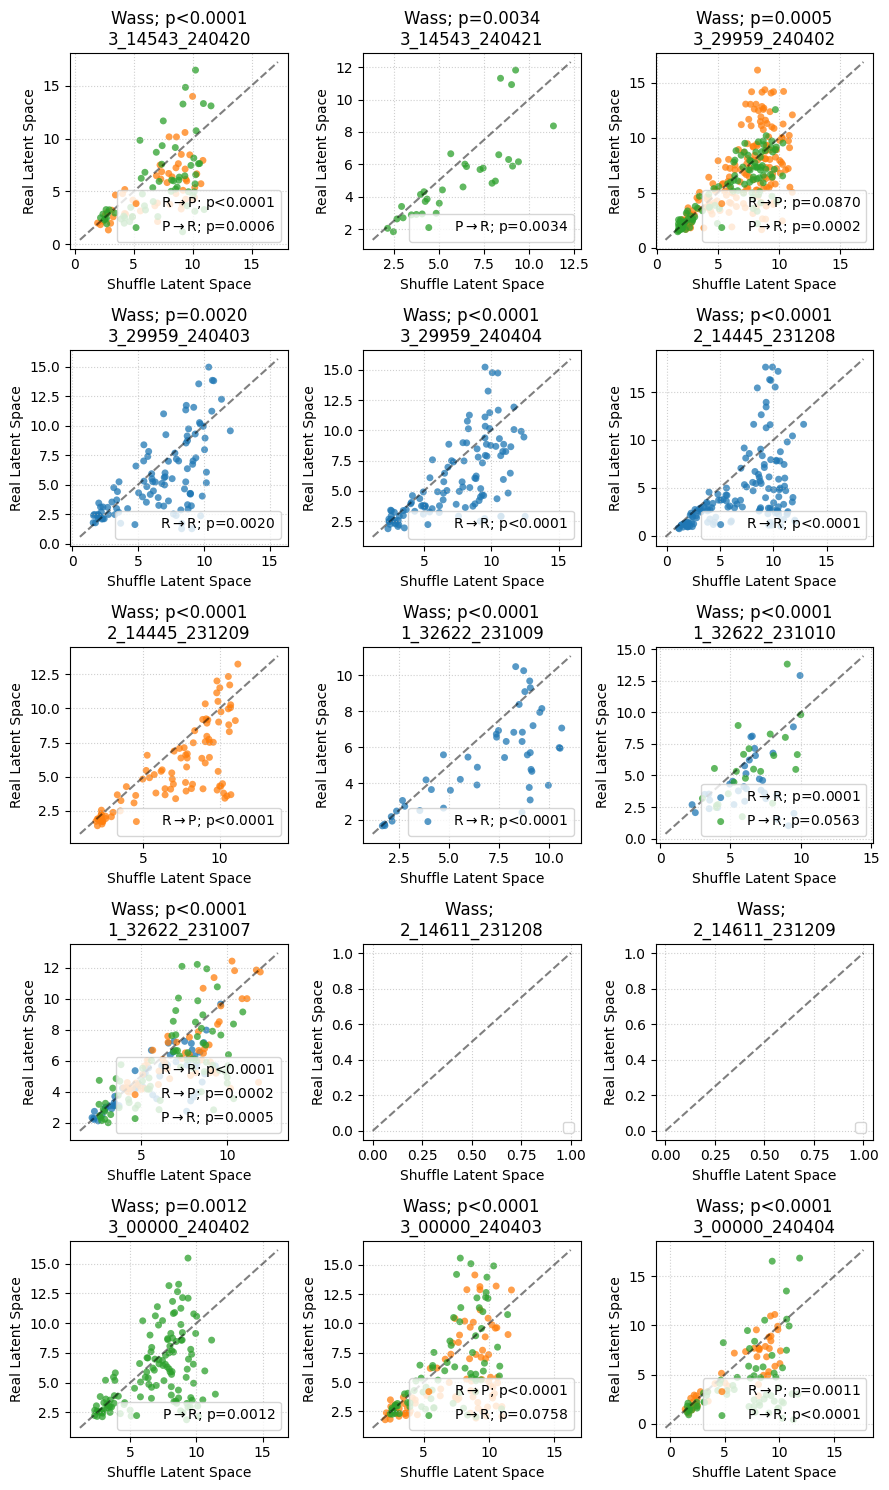

In [19]:
# Wass: shuffle test,  all sessions
session_names = list(dataloaders['test'].keys())
ncols = 3 
nrows = len(session_names) // ncols
# 1. Define the targets and colors (excluding ('Other',))
target_types = [
    ('Reward', 'Reward'), 
    ('Reward', 'Perch'), 
    ('Perch', 'Reward'), 
    ('Perch', 'Perch')
]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'] # Distinct professional palette
fig, axes = plt.subplots(nrows=nrows, ncols=ncols,figsize=(ncols*3,nrows*3))
for ii in range(nrows):
    for jj in range(ncols):
        session_to_analyze = list(dataloaders['test'].keys()) [ii * ncols + jj]
        # Get the empirical Jaccard dictionaries
        spatial_jac = spatial_sessions[session_to_analyze]
        all_real_lat_pool = []
        all_shuff_lat_pool = []
        # --- 2. Loop over each Flight Type and Evaluate Against Control ---
        for ft, color in zip(target_types, colors):
            if ft not in spatial_jac['flight_function_types']:
                continue
            # Extract empirical latent index per neuron
            real_lat_data = spatial_jac['flight_function_types'][ft]['wass_latent']
            # Run shuffle function for this specific flight type block
            # (Using 20 shuffles per neuron to establish a stable null distribution)
            # shuffle_dict = get_shuffled_jaccard_baseline(analyzer, ft_str=str(ft), n_shuffles=20)
            shuffle_dict = shuffle_sessions[session_to_analyze]['flight_function_types'][ft] # analyzer.get_shuffled_jaccard_baseline(ft_str=str(ft), n_shuffles=20)
            shuff_lat_data = shuffle_dict['latent']
            # Create mask to exclude NaN neurons (i.e., those that didn't spike)
            if len(shuff_lat_data) == 0:
                continue
            valid_mask = ~np.isnan(real_lat_data) & ~np.isnan(shuff_lat_data)
            
            real_lat_filtered = real_lat_data[valid_mask]
            shuff_lat_filtered = shuff_lat_data[valid_mask]
            if len(real_lat_filtered) == 0:
                continue
            all_real_lat_pool.extend(real_lat_filtered)
            all_shuff_lat_pool.extend(shuff_lat_filtered)
            
            # Compute statistical significance vs. its own behavioral occupancy baseline
            if len(real_lat_filtered) >= 5:
                _, p_val = wilcoxon(real_lat_filtered, shuff_lat_filtered, alternative='two-sided')
                p_str = f"p={p_val:.4f}" if p_val >= 0.0001 else "p<0.0001"
            else:
                p_str = "N too small"
                
            # Plot real vs shuffled values
            label_text = f"{ft[0][0]}$\\rightarrow${ft[1][0]}; {p_str}"
            axes[ii,jj].scatter(shuff_lat_filtered, real_lat_filtered, color=color, alpha=0.75, edgecolors='none', s=25, label=label_text)
        # --- 3. Compute Global Pool Statistics ---
        all_real_lat_pool = np.array(all_real_lat_pool)
        all_shuff_lat_pool = np.array(all_shuff_lat_pool)
        if len(all_real_lat_pool) >= 5:
            _, global_p = wilcoxon(all_real_lat_pool, all_shuff_lat_pool, alternative='two-sided')
            global_p_str = f"p={global_p:.4f}" if global_p >= 0.0001 else "p<0.0001"
        else:
            global_p_str = ""

        # Draw a identity diagonal reference line (y = x)
        min_val = min(axes[ii,jj].get_xlim()[0], axes[ii,jj].get_ylim()[0])
        max_val = max(axes[ii,jj].get_xlim()[1], axes[ii,jj].get_ylim()[1])
        axes[ii,jj].plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5)
        axes[ii,jj].set_xlabel('Shuffle Latent Space',)
        axes[ii,jj].set_ylabel('Real Latent Space',)
        axes[ii,jj].set_title(f"Wass; {global_p_str}\n{session_to_analyze[8:]}", )
        axes[ii,jj].legend(loc='lower right', frameon=True)
        axes[ii,jj].grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Main figure

## Summary

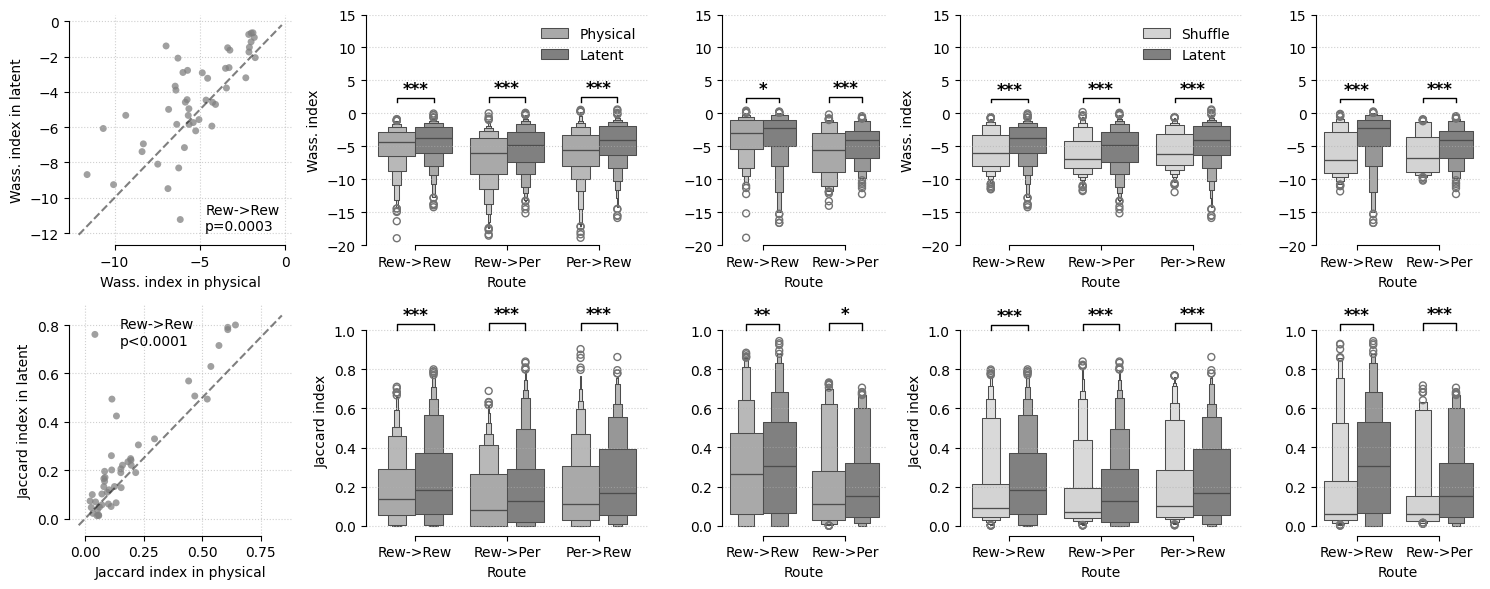

In [12]:
# 1. Define the targets and colors (excluding ('Other',))
target_types = [
    ('Reward', 'Reward'), 
    ('Reward', 'Perch'), 
    ('Perch', 'Reward'), 
    ('Perch', 'Perch')
]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'] # Distinct professional palette


fig, axes = plt.subplots(2, 5, figsize=(15, 6), gridspec_kw={'width_ratios': [3, 3.8, 2.2, 3.8, 2.2]})

# =================== first row: Wasserstein ================================
with open('./out/spatial_wasserstein.pkl', 'rb') as ff:
    spatial_sessions = pickle.load(ff)
with open('./out/spatial_wasserstein_shuffle.pkl', 'rb') as ff:
    shuffle_sessions = pickle.load(ff)

# example session
ax = axes[0,0]
session_to_analyze = 'Dataset_1_32622_231009' # 'Dataset_1_32622_231009', 'Dataset_3_14543_240421'
spatial = spatial_sessions[session_to_analyze]
# Track global arrays to perform an overall session-wide statistical test if needed
all_filtered_phys = []
all_filtered_lat = []
# 2. Loop over each flight functional type and plot
for ft, color in zip(target_types, colors):
    if ft not in spatial['flight_function_types']:
        continue
    phys_data = 1.0 - spatial['flight_function_types'][ft]['wass_physical']
    lat_data = 1.0 - spatial['flight_function_types'][ft]['wass_latent']
    # Create a mask to exclude NaN values on a per-neuron basis
    valid_mask = ~np.isnan(phys_data) & ~np.isnan(lat_data)
    phys_filtered = phys_data[valid_mask]
    lat_filtered = lat_data[valid_mask]
    if len(phys_filtered) == 0:
        continue
    all_filtered_phys.extend(phys_filtered)
    all_filtered_lat.extend(lat_filtered)
    # Calculate p-value for this specific functional type
    # A minimum of 20 samples is typically preferred for stable Wilcoxon testing asymptotics
    if len(phys_filtered) >= 5:
        _, p_val = wilcoxon(lat_filtered, phys_filtered, alternative='two-sided')
        p_str = f"p={p_val:.4f}" if p_val >= 0.0001 else "p<0.0001"
    else:
        p_str = "N too small"
    # Plot the scatter points for this type
    label_text = f"{ft[0][:3]}->{ft[1][:3]}\n{p_str}"
    ax.scatter(phys_filtered, lat_filtered, color='gray', alpha=0.75, edgecolors='none', s=25, label=label_text)
# 3. Calculate global session statistical markers
all_filtered_phys = np.array(all_filtered_phys)
all_filtered_lat = np.array(all_filtered_lat)
if len(all_filtered_phys) >= 5:
    _, global_p = wilcoxon(all_filtered_lat, all_filtered_phys, alternative='two-sided')
    global_p_str = f"p={global_p:.4f}" if global_p >= 0.0001 else "p<0.0001"
else:
    global_p_str = ""
# Draw a identity diagonal reference line (y = x)
min_val = min(ax.get_xlim()[0], ax.get_ylim()[0])
max_val = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5)
ax.set_xlabel('Wass. index in physical',)
ax.set_ylabel('Wass. index in latent',)
# ax.set_title(f"Jaccard; {global_p_str}\n{session_to_analyze[8:]}", )
ax.legend(loc='best', frameon=False)
ax.grid(True, linestyle=':', alpha=0.6)
sns.despine(ax=ax, trim=True)


# latent vs. physical for different routes
axes_tmp = [axes[0,1], axes[0,2]]
# Tracking framework separated by environment condition
env_aggregation = {
    'Indoor':  {ft: {'phys': [], 'lat': []} for ft in target_types},
    'Outdoor': {ft: {'phys': [], 'lat': []} for ft in target_types}
}
# --- 2. Extract and Group Data Across All Sessions ---
for session_to_analyze in list(dataloaders['test'].keys()):
    # Classify session environment
    if 'Dataset_1' in session_to_analyze or 'Dataset_3' in session_to_analyze:
        env_key = 'Indoor'
    elif 'Dataset_2' in session_to_analyze:
        env_key = 'Outdoor'
    else:
        continue  # Skip unclassified sessions
    # extract data
    spatial = spatial_sessions[session_to_analyze]
    shuffle = shuffle_sessions[session_to_analyze]
    for ft in target_types:
        if ft not in spatial['flight_function_types']:
            continue
        phys_data = 1.0 - spatial['flight_function_types'][ft]['wass_physical']
        lat_data = 1.0 - spatial['flight_function_types'][ft]['wass_latent']
        # Clean out NaNs for paired evaluations
        valid_mask = ~np.isnan(phys_data) & ~np.isnan(lat_data)
        phys_filtered = phys_data[valid_mask]
        lat_filtered = lat_data[valid_mask]
        if len(phys_filtered) == 0:
            continue
        env_aggregation[env_key][ft]['phys'].extend(phys_filtered)
        env_aggregation[env_key][ft]['lat'].extend(lat_filtered)
# --- 3. Construct DataFrames and Plot ---
env_keys = ['Indoor', 'Outdoor']
palette_dict = {'Physical': 'darkgray', 'Latent': 'gray'}
for idx, env in enumerate(env_keys):
    ax = axes_tmp[idx]
    records = []
    all_env_phys = []
    all_env_lat = []
    category_p_vals = []  # Store p-values along with the categorical index
    # Process each flight function type within this environment
    for cat_idx, ft in enumerate(target_types):
        phys_arr = np.array(env_aggregation[env][ft]['phys'])
        lat_arr = np.array(env_aggregation[env][ft]['lat'])
        n_samples = len(phys_arr)
        if n_samples == 0:
            continue
        all_env_phys.extend(phys_arr)
        all_env_lat.extend(lat_arr)
        # Compute category specific significance
        if n_samples >= 5:
            _, p_val = wilcoxon(lat_arr, phys_arr, alternative='two-sided')
            p_str = f"p={p_val:.4f}" if p_val >= 0.0001 else "p<0.0001"
        else:
            p_str = "N too small"
        # Save p_val and the x-index position for the bracket drawing
        category_p_vals.append((cat_idx, p_val))
        # Format the x-axis tick text with statistics
        label_string = f"{ft[0][:3]}->{ft[1][:3]}"
        for p_val_item in phys_arr:
            records.append({'Category': label_string, 'Index': p_val_item, 'Space': 'Physical'})
        for l_val_item in lat_arr:
            records.append({'Category': label_string, 'Index': l_val_item, 'Space': 'Latent'})   
    if len(records) == 0:
        ax.set_title(f"{env} (No Data Available)")
        continue
    # data frame
    df_env_plot = pd.DataFrame(records)
    # Compute environment global pool significance score
    all_env_phys = np.array(all_env_phys)
    all_env_lat = np.array(all_env_lat)
    _, env_global_p = wilcoxon(all_env_lat, all_env_phys, alternative='two-sided')
    env_global_p_str = f"Global p={env_global_p:.4f}" if env_global_p >= 0.0001 else "Global p<0.0001"
    # Draw the boxen plot for this environment
    sns.boxenplot(
        data=df_env_plot, 
        x='Category', 
        y='Index', 
        hue='Space',
        palette=palette_dict,
        outlier_prop=0.05,
        ax=ax
    )
    # --- ADD SIGNIFICANCE BRACKETS ---
    # Draw bracket for each route category between Physical (-0.2) and Latent (+0.2)
    for c_idx, p_val in category_p_vals:
        x1 = c_idx - 0.2  # Center of Physical box
        x2 = c_idx + 0.2  # Center of Latent box
        # Place bracket slightly above 0 (or adjust y as needed)
        add_significance_bracket(ax, x1=x1, x2=x2, p=p_val, y=1.7, height_frac=0.03)
    # Formatting details per subplot
    # ax.set_title(f"{env}; Pooled sessions; {env_global_p_str}", fontsize=12, fontweight='bold', pad=12)
    ax.set_xlabel('Route')
    ax.grid(axis='y', linestyle=':', alpha=0.6)
    ax.set_ylim(-20, 15)
    sns.despine(ax=ax, trim=True)
    # Clean up secondary labels to maintain clean alignment
    if idx == 0:
        ax.set_ylabel('Wass. index')
        ax.legend(loc='upper right', frameon=False)
    else:
        ax.set_ylabel('')
        ax.get_legend().remove() # Use master legend present on first subplot axis


# latent vs. shuffle for different routes
axes_tmp = [axes[0,3], axes[0,4]]
# Tracking framework separated by environment condition
env_aggregation = {
    'Indoor':  {ft: {'phys': [], 'lat': []} for ft in target_types},
    'Outdoor': {ft: {'phys': [], 'lat': []} for ft in target_types}
}
# --- 2. Extract and Group Data Across All Sessions ---
for session_to_analyze in list(dataloaders['test'].keys()):
    # Classify session environment
    if 'Dataset_1' in session_to_analyze or 'Dataset_3' in session_to_analyze:
        env_key = 'Indoor'
    elif 'Dataset_2' in session_to_analyze:
        env_key = 'Outdoor'
    else:
        continue  # Skip unclassified sessions
    # extract data
    spatial = spatial_sessions[session_to_analyze]
    shuffle = shuffle_sessions[session_to_analyze]
    for ft in target_types:
        if ft not in spatial['flight_function_types']:
            continue
        if len(shuffle['flight_function_types'][ft]['latent']) == 0:
            continue
        shuf_data = 1.0 - shuffle['flight_function_types'][ft]['latent']
        lat_data = 1.0 - spatial['flight_function_types'][ft]['wass_latent']
        # Clean out NaNs for paired evaluations
        valid_mask = ~np.isnan(shuf_data) & ~np.isnan(lat_data)
        shuf_filtered = shuf_data[valid_mask]
        lat_filtered = lat_data[valid_mask]
        if len(shuf_filtered) == 0:
            continue
        env_aggregation[env_key][ft]['phys'].extend(shuf_filtered)
        env_aggregation[env_key][ft]['lat'].extend(lat_filtered)
# --- 3. Construct DataFrames and Plot ---
env_keys = ['Indoor', 'Outdoor']
palette_dict = {'Shuffle': 'lightgray', 'Latent': 'gray'}
for idx, env in enumerate(env_keys):
    ax = axes_tmp[idx]
    records = []
    all_env_phys = []
    all_env_lat = []
    category_p_vals = []  # Store p-values along with the categorical index
    # Process each flight function type within this environment
    for cat_idx, ft in enumerate(target_types):
        phys_arr = np.array(env_aggregation[env][ft]['phys'])
        lat_arr = np.array(env_aggregation[env][ft]['lat'])
        n_samples = len(phys_arr)
        if n_samples == 0:
            continue
        all_env_phys.extend(phys_arr)
        all_env_lat.extend(lat_arr)
        # Compute category specific significance
        if n_samples >= 5:
            _, p_val = wilcoxon(lat_arr, phys_arr, alternative='two-sided')
            p_str = f"p={p_val:.4f}" if p_val >= 0.0001 else "p<0.0001"
        else:
            p_str = "N too small"
        # Save p_val and the x-index position for the bracket drawing
        category_p_vals.append((cat_idx, p_val))
        # Format the x-axis tick text with statistics
        label_string = f"{ft[0][:3]}->{ft[1][:3]}"
        for p_val_item in phys_arr:
            records.append({'Category': label_string, 'Index': p_val_item, 'Space': 'Shuffle'})
        for l_val_item in lat_arr:
            records.append({'Category': label_string, 'Index': l_val_item, 'Space': 'Latent'})   
    if len(records) == 0:
        ax.set_title(f"{env} (No Data Available)")
        continue
    # data frame
    df_env_plot = pd.DataFrame(records)
    # Compute environment global pool significance score
    all_env_phys = np.array(all_env_phys)
    all_env_lat = np.array(all_env_lat)
    _, env_global_p = wilcoxon(all_env_lat, all_env_phys, alternative='two-sided')
    env_global_p_str = f"Global p={env_global_p:.4f}" if env_global_p >= 0.0001 else "Global p<0.0001"
    # Draw the boxen plot for this environment
    sns.boxenplot(
        data=df_env_plot, 
        x='Category', 
        y='Index', 
        hue='Space',
        palette=palette_dict,
        outlier_prop=0.05,
        ax=ax
    )
    # --- ADD SIGNIFICANCE BRACKETS ---
    # Draw bracket for each route category between Physical (-0.2) and Latent (+0.2)
    for c_idx, p_val in category_p_vals:
        x1 = c_idx - 0.2  # Center of Physical box
        x2 = c_idx + 0.2  # Center of Latent box
        # Place bracket slightly above 0 (or adjust y as needed)
        add_significance_bracket(ax, x1=x1, x2=x2, p=p_val, y=1.7, height_frac=0.03)
    # Formatting details per subplot
    # ax.set_title(f"{env}; Pooled sessions; {env_global_p_str}", fontsize=12, fontweight='bold', pad=12)
    ax.set_xlabel('Route')
    ax.grid(axis='y', linestyle=':', alpha=0.6)
    ax.set_ylim(-20, 15)
    sns.despine(ax=ax, trim=True)
    # Clean up secondary labels to maintain clean alignment
    if idx == 0:
        ax.set_ylabel('Wass. index')
        ax.legend(loc='upper right', frameon=False)
    else:
        ax.set_ylabel('')
        ax.get_legend().remove() # Use master legend present on first subplot axis


# =================== second row: Jaccard ================================
with open('./out/spatial_jaccard.pkl', 'rb') as ff:
    spatial_sessions = pickle.load(ff)
with open('./out/spatial_jaccard_shuffle.pkl', 'rb') as ff:
    shuffle_sessions = pickle.load(ff)

# example session
ax = axes[1,0]
session_to_analyze = 'Dataset_1_32622_231009' # 'Dataset_1_32622_231009', 'Dataset_3_14543_240421'
spatial = spatial_sessions[session_to_analyze]
# Track global arrays to perform an overall session-wide statistical test if needed
all_filtered_phys = []
all_filtered_lat = []
# 2. Loop over each flight functional type and plot
for ft, color in zip(target_types, colors):
    if ft not in spatial['flight_function_types']:
        continue
    phys_data = spatial['flight_function_types'][ft]['jaccard_physical']
    lat_data = spatial['flight_function_types'][ft]['jaccard_latent']
    # Create a mask to exclude NaN values on a per-neuron basis
    valid_mask = ~np.isnan(phys_data) & ~np.isnan(lat_data)
    phys_filtered = phys_data[valid_mask]
    lat_filtered = lat_data[valid_mask]
    if len(phys_filtered) == 0:
        continue
    all_filtered_phys.extend(phys_filtered)
    all_filtered_lat.extend(lat_filtered)
    # Calculate p-value for this specific functional type
    # A minimum of 20 samples is typically preferred for stable Wilcoxon testing asymptotics
    if len(phys_filtered) >= 5:
        _, p_val = wilcoxon(lat_filtered, phys_filtered, alternative='two-sided')
        p_str = f"p={p_val:.4f}" if p_val >= 0.0001 else "p<0.0001"
    else:
        p_str = "N too small"
    # Plot the scatter points for this type
    label_text = f"{ft[0][:3]}->{ft[1][:3]}\n{p_str}"
    ax.scatter(phys_filtered, lat_filtered, color='gray', alpha=0.75, edgecolors='none', s=25, label=label_text)
# 3. Calculate global session statistical markers
all_filtered_phys = np.array(all_filtered_phys)
all_filtered_lat = np.array(all_filtered_lat)
if len(all_filtered_phys) >= 5:
    _, global_p = wilcoxon(all_filtered_lat, all_filtered_phys, alternative='two-sided')
    global_p_str = f"p={global_p:.4f}" if global_p >= 0.0001 else "p<0.0001"
else:
    global_p_str = ""
# Draw a identity diagonal reference line (y = x)
min_val = min(ax.get_xlim()[0], ax.get_ylim()[0])
max_val = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5)
ax.set_xlabel('Jaccard index in physical',)
ax.set_ylabel('Jaccard index in latent',)
# ax.set_title(f"Jaccard; {global_p_str}\n{session_to_analyze[8:]}", )
ax.legend(loc='best', frameon=False)
ax.grid(True, linestyle=':', alpha=0.6)
sns.despine(ax=ax, trim=True)


# latent vs. physical for different routes
axes_tmp = [axes[1,1], axes[1,2]]
# Tracking framework separated by environment condition
env_aggregation = {
    'Indoor':  {ft: {'phys': [], 'lat': []} for ft in target_types},
    'Outdoor': {ft: {'phys': [], 'lat': []} for ft in target_types}
}
# --- 2. Extract and Group Data Across All Sessions ---
for session_to_analyze in list(dataloaders['test'].keys()):
    # Classify session environment
    if 'Dataset_1' in session_to_analyze or 'Dataset_3' in session_to_analyze:
        env_key = 'Indoor'
    elif 'Dataset_2' in session_to_analyze:
        env_key = 'Outdoor'
    else:
        continue  # Skip unclassified sessions
    # extract data
    spatial = spatial_sessions[session_to_analyze]
    for ft in target_types:
        if ft not in spatial['flight_function_types']:
            continue
        phys_data = spatial['flight_function_types'][ft]['jaccard_physical']
        lat_data = spatial['flight_function_types'][ft]['jaccard_latent']
        # Clean out NaNs for paired evaluations
        valid_mask = ~np.isnan(phys_data) & ~np.isnan(lat_data)
        phys_filtered = phys_data[valid_mask]
        lat_filtered = lat_data[valid_mask]
        if len(phys_filtered) == 0:
            continue
        env_aggregation[env_key][ft]['phys'].extend(phys_filtered)
        env_aggregation[env_key][ft]['lat'].extend(lat_filtered)
# --- 3. Construct DataFrames and Plot ---
env_keys = ['Indoor', 'Outdoor']
palette_dict = {'Physical': 'darkgray', 'Latent': 'gray'}
for idx, env in enumerate(env_keys):
    ax = axes_tmp[idx]
    records = []
    all_env_phys = []
    all_env_lat = []
    category_p_vals = []  # Store p-values along with the categorical index
    # Process each flight function type within this environment
    for cat_idx, ft in enumerate(target_types):
        phys_arr = np.array(env_aggregation[env][ft]['phys'])
        lat_arr = np.array(env_aggregation[env][ft]['lat'])
        n_samples = len(phys_arr)
        if n_samples == 0:
            continue
            
        all_env_phys.extend(phys_arr)
        all_env_lat.extend(lat_arr)
        # Compute category specific significance
        if n_samples >= 5:
            _, p_val = wilcoxon(lat_arr, phys_arr, alternative='two-sided')
            p_str = f"p={p_val:.4f}" if p_val >= 0.0001 else "p<0.0001"
        else:
            p_str = "N too small"
        # Save p_val and the x-index position for the bracket drawing
        category_p_vals.append((cat_idx, p_val))
        # Format the x-axis tick text with statistics
        label_string = f"{ft[0][:3]}->{ft[1][:3]}"
        for p_val_item in phys_arr:
            records.append({'Category': label_string, 'Index': p_val_item, 'Space': 'Physical'})
        for l_val_item in lat_arr:
            records.append({'Category': label_string, 'Index': l_val_item, 'Space': 'Latent'})   
    if len(records) == 0:
        ax.set_title(f"{env} (No Data Available)")
        continue
    # data frame
    df_env_plot = pd.DataFrame(records)
    # Compute environment global pool significance score
    all_env_phys = np.array(all_env_phys)
    all_env_lat = np.array(all_env_lat)
    _, env_global_p = wilcoxon(all_env_lat, all_env_phys, alternative='two-sided')
    env_global_p_str = f"Global p={env_global_p:.4f}" if env_global_p >= 0.0001 else "Global p<0.0001"
    # Draw the boxen plot for this environment
    sns.boxenplot(
        data=df_env_plot, 
        x='Category', 
        y='Index', 
        hue='Space',
        palette=palette_dict,
        outlier_prop=0.05,
        ax=ax
    )
    # --- ADD SIGNIFICANCE BRACKETS ---
    # Draw bracket for each route category between Physical (-0.2) and Latent (+0.2)
    for c_idx, p_val in category_p_vals:
        x1 = c_idx - 0.2  # Center of Physical box
        x2 = c_idx + 0.2  # Center of Latent box
        # Place bracket slightly above 0 (or adjust y as needed)
        add_significance_bracket(ax, x1=x1, x2=x2, p=p_val, y=1.0, height_frac=0.03)
    # Formatting details per subplot
    # ax.set_title(f"{env}; Pooled sessions; {env_global_p_str}", fontsize=12, fontweight='bold', pad=12)
    ax.set_xlabel('Route')
    ax.grid(axis='y', linestyle=':', alpha=0.6)
    # ax.set_ylim(-20, 15)
    sns.despine(ax=ax, trim=True)
    # Clean up secondary labels to maintain clean alignment
    if idx == 0:
        ax.set_ylabel('Jaccard index')
        # ax.legend(loc='upper right', frameon=False)
        ax.get_legend().remove() # Use master legend present on first subplot axis
    else:
        ax.set_ylabel('')
        ax.get_legend().remove() # Use master legend present on first subplot axis


# latent vs. shuffle for different routes
axes_tmp = [axes[1,3], axes[1,4]]
# Tracking framework separated by environment condition
env_aggregation = {
    'Indoor':  {ft: {'phys': [], 'lat': []} for ft in target_types},
    'Outdoor': {ft: {'phys': [], 'lat': []} for ft in target_types}
}
# --- 2. Extract and Group Data Across All Sessions ---
for session_to_analyze in list(dataloaders['test'].keys()):
    # Classify session environment
    if 'Dataset_1' in session_to_analyze or 'Dataset_3' in session_to_analyze:
        env_key = 'Indoor'
    elif 'Dataset_2' in session_to_analyze:
        env_key = 'Outdoor'
    else:
        continue  # Skip unclassified sessions
    # extract data
    spatial = spatial_sessions[session_to_analyze]
    shuffle = shuffle_sessions[session_to_analyze]
    for ft in target_types:
        if ft not in spatial['flight_function_types']:
            continue
        if len(shuffle['flight_function_types'][ft]['latent']) == 0:
            continue
        shuf_data = shuffle['flight_function_types'][ft]['latent']
        lat_data = spatial['flight_function_types'][ft]['jaccard_latent']
        # Clean out NaNs for paired evaluations
        valid_mask = ~np.isnan(shuf_data) & ~np.isnan(lat_data)
        shuf_filtered = shuf_data[valid_mask]
        lat_filtered = lat_data[valid_mask]
        if len(shuf_filtered) == 0:
            continue
        env_aggregation[env_key][ft]['phys'].extend(shuf_filtered)
        env_aggregation[env_key][ft]['lat'].extend(lat_filtered)
# --- 3. Construct DataFrames and Plot ---
env_keys = ['Indoor', 'Outdoor']
palette_dict = {'Shuffle': 'lightgray', 'Latent': 'gray'}
for idx, env in enumerate(env_keys):
    ax = axes_tmp[idx]
    records = []
    all_env_phys = []
    all_env_lat = []
    category_p_vals = []  # Store p-values along with the categorical index
    # Process each flight function type within this environment
    for cat_idx, ft in enumerate(target_types):
        phys_arr = np.array(env_aggregation[env][ft]['phys'])
        lat_arr = np.array(env_aggregation[env][ft]['lat'])
        n_samples = len(phys_arr)
        if n_samples == 0:
            continue
        all_env_phys.extend(phys_arr)
        all_env_lat.extend(lat_arr)
        # Compute category specific significance
        if n_samples >= 5:
            _, p_val = wilcoxon(lat_arr, phys_arr, alternative='two-sided')
            p_str = f"p={p_val:.4f}" if p_val >= 0.0001 else "p<0.0001"
        else:
            p_str = "N too small"
        # Save p_val and the x-index position for the bracket drawing
        category_p_vals.append((cat_idx, p_val))
        # Format the x-axis tick text with statistics
        label_string = f"{ft[0][:3]}->{ft[1][:3]}"
        for p_val_item in phys_arr:
            records.append({'Category': label_string, 'Index': p_val_item, 'Space': 'Shuffle'})
        for l_val_item in lat_arr:
            records.append({'Category': label_string, 'Index': l_val_item, 'Space': 'Latent'})   
    if len(records) == 0:
        ax.set_title(f"{env} (No Data Available)")
        continue
    # data frame
    df_env_plot = pd.DataFrame(records)
    # Compute environment global pool significance score
    all_env_phys = np.array(all_env_phys)
    all_env_lat = np.array(all_env_lat)
    _, env_global_p = wilcoxon(all_env_lat, all_env_phys, alternative='two-sided')
    env_global_p_str = f"Global p={env_global_p:.4f}" if env_global_p >= 0.0001 else "Global p<0.0001"
    # Draw the boxen plot for this environment
    sns.boxenplot(
        data=df_env_plot, 
        x='Category', 
        y='Index', 
        hue='Space',
        palette=palette_dict,
        outlier_prop=0.05,
        ax=ax
    )
    # --- ADD SIGNIFICANCE BRACKETS ---
    # Draw bracket for each route category between Physical (-0.2) and Latent (+0.2)
    for c_idx, p_val in category_p_vals:
        x1 = c_idx - 0.2  # Center of Physical box
        x2 = c_idx + 0.2  # Center of Latent box
        # Place bracket slightly above 0 (or adjust y as needed)
        add_significance_bracket(ax, x1=x1, x2=x2, p=p_val, y=1.0, height_frac=0.03)
    # Formatting details per subplot
    # ax.set_title(f"{env}; Pooled sessions; {env_global_p_str}", fontsize=12, fontweight='bold', pad=12)
    ax.set_xlabel('Route')
    ax.grid(axis='y', linestyle=':', alpha=0.6)
    # ax.set_ylim(-20, 15)
    sns.despine(ax=ax, trim=True)
    # Clean up secondary labels to maintain clean alignment
    if idx == 0:
        ax.set_ylabel('Jaccard index')
        # ax.legend(loc='upper right', frameon=False)
        ax.get_legend().remove() # Use master legend present on first subplot axis
    else:
        ax.set_ylabel('')
        ax.get_legend().remove() # Use master legend present on first subplot axis

# for ax in axes:
#     sns.despine(ax=ax, trim=True)
plt.tight_layout()

# plt.savefig(f"./out-figures/fig4-summary.svg", dpi=300)
# plt.savefig(f"./out-figures/fig4-summary.png", dpi=300)

In [15]:
shuffle['flight_function_types']

{('Reward',
  'Perch'): {'physical': array([0.27724713, 0.05881353, 0.12308271, 0.13640467, 0.05099818,
         0.45386931, 0.1801352 ,        nan, 0.41245655,        nan,
         0.4478865 , 0.4519123 ,        nan, 0.05067152,        nan,
                nan,        nan, 0.02050441,        nan,        nan,
         0.04160295,        nan, 0.02597242, 0.02978861, 0.05009165,
         0.04138821, 0.04498086,        nan,        nan, 0.03289041,
                nan, 0.16138536, 0.04126564, 0.02017288, 0.03665221,
         0.06879355, 0.07181012, 0.03748691, 0.42275439, 0.21259547,
         0.45403296,        nan, 0.11464439, 0.02293624,        nan,
         0.01778229, 0.02609266,        nan,        nan,        nan,
         0.10438063, 0.13390298,        nan, 0.01334627, 0.03489918,
         0.10882753,        nan, 0.08673048, 0.13539192, 0.02086775,
                nan,        nan, 0.02445612,        nan,        nan,
         0.03895798, 0.07453326, 0.03509809, 0.25197067,        nan,

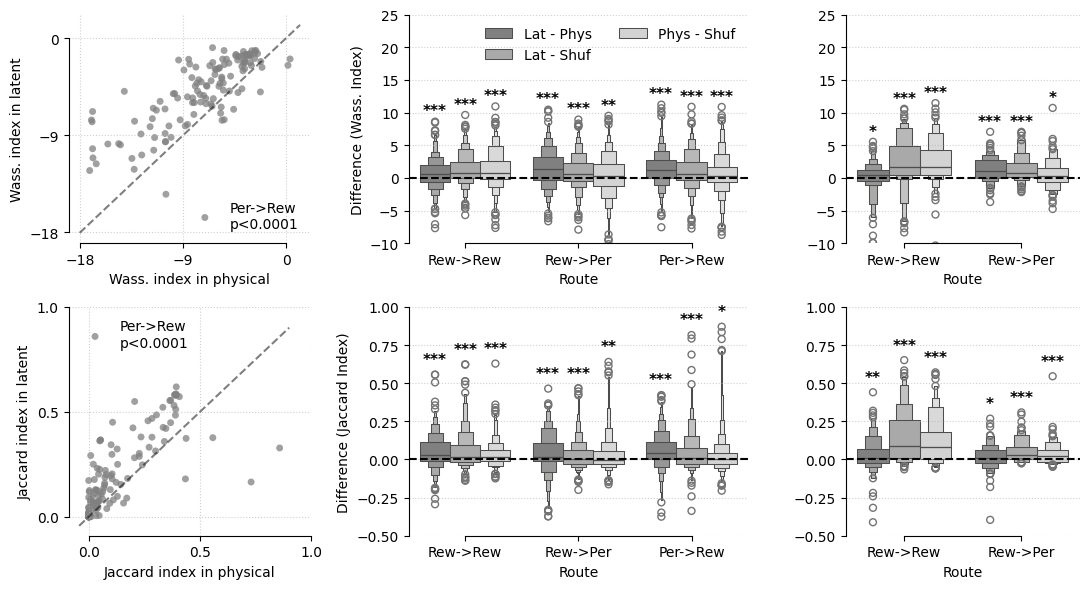

In [37]:
# 1. Define the targets and colors (excluding ('Other',))
target_types = [
    ('Reward', 'Reward'), 
    ('Reward', 'Perch'), 
    ('Perch', 'Reward'), 
    ('Perch', 'Perch')
]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'] # Distinct professional palette


fig, axes = plt.subplots(2, 3, figsize=(11, 6), gridspec_kw={'width_ratios': [3, 4.2, 2.9]})

# =================== first row: Wasserstein ================================
with open('./out/spatial_wasserstein.pkl', 'rb') as ff:
    spatial_sessions = pickle.load(ff)
with open('./out/spatial_wasserstein_shuffle.pkl', 'rb') as ff:
    shuffle_sessions = pickle.load(ff)

# example session
ax = axes[0,0]
session_to_analyze = 'Dataset_3_00000_240402' # 'Dataset_1_32622_231009', 'Dataset_3_14543_240421'
spatial = spatial_sessions[session_to_analyze]
# Track global arrays to perform an overall session-wide statistical test if needed
all_filtered_phys = []
all_filtered_lat = []
# 2. Loop over each flight functional type and plot
for ft, color in zip(target_types, colors):
    if ft not in spatial['flight_function_types']:
        continue
    phys_data = 1.0 - spatial['flight_function_types'][ft]['wass_physical']
    lat_data = 1.0 - spatial['flight_function_types'][ft]['wass_latent']
    # Create a mask to exclude NaN values on a per-neuron basis
    valid_mask = ~np.isnan(phys_data) & ~np.isnan(lat_data)
    phys_filtered = phys_data[valid_mask]
    lat_filtered = lat_data[valid_mask]
    if len(phys_filtered) == 0:
        continue
    all_filtered_phys.extend(phys_filtered)
    all_filtered_lat.extend(lat_filtered)
    # Calculate p-value for this specific functional type
    # A minimum of 20 samples is typically preferred for stable Wilcoxon testing asymptotics
    if len(phys_filtered) >= 5:
        _, p_val = wilcoxon(lat_filtered, phys_filtered, alternative='two-sided')
        p_str = f"p={p_val:.4f}" if p_val >= 0.0001 else "p<0.0001"
    else:
        p_str = "N too small"
    # Plot the scatter points for this type
    label_text = f"{ft[0][:3]}->{ft[1][:3]}\n{p_str}"
    ax.scatter(phys_filtered, lat_filtered, color='gray', alpha=0.75, edgecolors='none', s=25, label=label_text)
# 3. Calculate global session statistical markers
all_filtered_phys = np.array(all_filtered_phys)
all_filtered_lat = np.array(all_filtered_lat)
if len(all_filtered_phys) >= 5:
    _, global_p = wilcoxon(all_filtered_lat, all_filtered_phys, alternative='two-sided')
    global_p_str = f"p={global_p:.4f}" if global_p >= 0.0001 else "p<0.0001"
else:
    global_p_str = ""
# Draw a identity diagonal reference line (y = x)
min_val = min(ax.get_xlim()[0], ax.get_ylim()[0])
max_val = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5)
ax.set_xlabel('Wass. index in physical',)
ax.set_ylabel('Wass. index in latent',)
ax.set_xticks([-18, -9, 0])
ax.set_yticks([-18, -9, 0])
# ax.set_title(f"Jaccard; {global_p_str}\n{session_to_analyze[8:]}", )
ax.legend(loc='best', frameon=False)
ax.grid(True, linestyle=':', alpha=0.6)
sns.despine(ax=ax, trim=True)


# latent vs. physical  and latent vs. shuffle for different routes
axes_tmp = [axes[0, 1], axes[0, 2]]  # Panel 0: Indoor, Panel 1: Outdoor
env_keys = ['Indoor', 'Outdoor']
env_aggregation = {
    'Indoor':  {ft: {'lat_minus_phys': [], 'lat_minus_shuf': [], 'phys_minus_shuf': []} for ft in target_types},
    'Outdoor': {ft: {'lat_minus_phys': [], 'lat_minus_shuf': [], 'phys_minus_shuf': []} for ft in target_types}
}
# --- 2. Extract and Compute Differences Across Sessions ---
for session_to_analyze in list(dataloaders['test'].keys()):
    # Classify session environment
    if 'Dataset_1' in session_to_analyze or 'Dataset_3' in session_to_analyze:
        env_key = 'Indoor'
    elif 'Dataset_2' in session_to_analyze:
        env_key = 'Outdoor'
    else:
        continue
    spatial = spatial_sessions[session_to_analyze]
    shuffle = shuffle_sessions[session_to_analyze]
    for ft in target_types:
        if ft not in spatial['flight_function_types']:
            continue
        phys_data = 1.0 - spatial['flight_function_types'][ft]['wass_physical']
        lat_data = 1.0 - spatial['flight_function_types'][ft]['wass_latent']
        # Paired Latent vs. Physical difference
        valid_mask_phys = ~np.isnan(phys_data) & ~np.isnan(lat_data)
        if np.any(valid_mask_phys):
            diff_phys = lat_data[valid_mask_phys] - phys_data[valid_mask_phys]
            env_aggregation[env_key][ft]['lat_minus_phys'].extend(diff_phys)
        # Paired Latent vs. Shuffle difference
        if (ft in shuffle['flight_function_types'] and 
            len(shuffle['flight_function_types'][ft]['latent']) > 0):
            shuf_data = 1.0 - shuffle['flight_function_types'][ft]['latent']
            valid_mask_shuf = ~np.isnan(shuf_data) & ~np.isnan(lat_data)
            if np.any(valid_mask_shuf):
                diff_shuf = lat_data[valid_mask_shuf] - shuf_data[valid_mask_shuf]
                env_aggregation[env_key][ft]['lat_minus_shuf'].extend(diff_shuf)
        # Paired Physical vs. Shuffle difference
        if (ft in shuffle['flight_function_types'] and 
            len(shuffle['flight_function_types'][ft]['physical']) > 0):
            shuf_data = 1.0 - shuffle['flight_function_types'][ft]['physical']
            valid_mask_shuf = ~np.isnan(shuf_data) & ~np.isnan(phys_data)
            if np.any(valid_mask_shuf):
                diff_shuf = phys_data[valid_mask_shuf] - shuf_data[valid_mask_shuf]
                env_aggregation[env_key][ft]['phys_minus_shuf'].extend(diff_shuf)

# --- 3. Construct DataFrames, Plot, and Annotate Stars ---
palette_dict = {'Lat - Phys': 'gray', 'Lat - Shuf': 'darkgray', 'Phys - Shuf': 'lightgray'}
for idx, env in enumerate(env_keys):
    ax = axes_tmp[idx]
    records = []
    sig_annotations = []  # Stores (x_position, p_value, max_val)
    for cat_idx, ft in enumerate(target_types):
        diff_phys_arr = np.array(env_aggregation[env][ft]['lat_minus_phys'])
        diff_shuf_arr = np.array(env_aggregation[env][ft]['lat_minus_shuf'])
        diff_shuf_arr_phys = np.array(env_aggregation[env][ft]['phys_minus_shuf'])
        label_string = f"{ft[0][:3]}->{ft[1][:3]}"
        # Latent - Physical stats & records
        if len(diff_phys_arr) > 0:
            for val in diff_phys_arr:
                records.append({'Category': label_string, 'Diff': val, 'Comparison': 'Lat - Phys'})
            p_phys = wilcoxon(diff_phys_arr, alternative='two-sided').pvalue if len(diff_phys_arr) >= 5 else None
            # Box for 'Lat - Phys' is shifted to -0.2 relative to category index
            sig_annotations.append((cat_idx - 0.27, p_phys, np.max(diff_phys_arr)))
        # Latent - Shuffle stats & records
        if len(diff_shuf_arr) > 0:
            for val in diff_shuf_arr:
                records.append({'Category': label_string, 'Diff': val, 'Comparison': 'Lat - Shuf'})
            p_shuf = wilcoxon(diff_shuf_arr, alternative='two-sided').pvalue if len(diff_shuf_arr) >= 5 else None
            # Box for 'Lat - Shuf' is shifted to +0.2 relative to category index
            sig_annotations.append((cat_idx + 0.0, p_shuf, np.max(diff_shuf_arr)))
        # Physical - Shuffle stats & records
        if len(diff_shuf_arr_phys) > 0:
            for val in diff_shuf_arr_phys:
                records.append({'Category': label_string, 'Diff': val, 'Comparison': 'Phys - Shuf'})
            p_shuf = wilcoxon(diff_shuf_arr_phys, alternative='two-sided').pvalue if len(diff_shuf_arr_phys) >= 5 else None
            # Box for 'Lat - Shuf' is shifted to +0.2 relative to category index
            sig_annotations.append((cat_idx + 0.27, p_shuf, np.max(diff_shuf_arr_phys)))

    if len(records) == 0:
        ax.set_title(f"{env} (No Data Available)")
        continue
    df_env_plot = pd.DataFrame(records)
    # Draw boxenplot with 2 hue categories per route
    sns.boxenplot(
        data=df_env_plot,
        x='Category',
        y='Diff',
        hue='Comparison',
        palette=palette_dict,
        outlier_prop=0.05,
        ax=ax
    )
    # --- Add Significance Stars Directly Above Boxes ---
    for x_pos, p_val, max_val in sig_annotations:
        stars = stars_for_p(p_val)
        if stars:
            # Position text slightly above the maximum data point for that specific box
            y_pos = max_val + 0.5 
            ax.text(
                x_pos, y_pos, stars,
                ha='center', va='bottom',
                fontsize=11, fontweight='bold', color='black'
            )
    # Formatting details
    # ax.set_title(env, fontsize=12, fontweight='bold')
    ax.set_xlabel('Route')
    ax.grid(axis='y', linestyle=':', alpha=0.6)
    ax.axhline(y=0, c='k', linestyle='--')
    ax.set_ylim(-10, 25)
    sns.despine(ax=ax, trim=True)
    if idx == 0:
        ax.set_ylabel('Difference (Wass. Index)')
        ax.legend(loc='upper right', frameon=False, ncol=2)
    else:
        ax.set_ylabel('')
        if ax.get_legend() is not None:
            ax.get_legend().remove()


# =================== second row: Jaccard ================================
with open('./out/spatial_jaccard.pkl', 'rb') as ff:
    spatial_sessions = pickle.load(ff)
with open('./out/spatial_jaccard_shuffle.pkl', 'rb') as ff:
    shuffle_sessions = pickle.load(ff)

# example session
ax = axes[1,0]
session_to_analyze = 'Dataset_3_00000_240402' # 'Dataset_1_32622_231009', 'Dataset_3_14543_240421'
spatial = spatial_sessions[session_to_analyze]
# Track global arrays to perform an overall session-wide statistical test if needed
all_filtered_phys = []
all_filtered_lat = []
# 2. Loop over each flight functional type and plot
for ft, color in zip(target_types, colors):
    if ft not in spatial['flight_function_types']:
        continue
    phys_data = spatial['flight_function_types'][ft]['jaccard_physical']
    lat_data = spatial['flight_function_types'][ft]['jaccard_latent']
    # Create a mask to exclude NaN values on a per-neuron basis
    valid_mask = ~np.isnan(phys_data) & ~np.isnan(lat_data)
    phys_filtered = phys_data[valid_mask]
    lat_filtered = lat_data[valid_mask]
    if len(phys_filtered) == 0:
        continue
    all_filtered_phys.extend(phys_filtered)
    all_filtered_lat.extend(lat_filtered)
    # Calculate p-value for this specific functional type
    # A minimum of 20 samples is typically preferred for stable Wilcoxon testing asymptotics
    if len(phys_filtered) >= 5:
        _, p_val = wilcoxon(lat_filtered, phys_filtered, alternative='two-sided')
        p_str = f"p={p_val:.4f}" if p_val >= 0.0001 else "p<0.0001"
    else:
        p_str = "N too small"
    # Plot the scatter points for this type
    label_text = f"{ft[0][:3]}->{ft[1][:3]}\n{p_str}"
    ax.scatter(phys_filtered, lat_filtered, color='gray', alpha=0.75, edgecolors='none', s=25, label=label_text)
# 3. Calculate global session statistical markers
all_filtered_phys = np.array(all_filtered_phys)
all_filtered_lat = np.array(all_filtered_lat)
if len(all_filtered_phys) >= 5:
    _, global_p = wilcoxon(all_filtered_lat, all_filtered_phys, alternative='two-sided')
    global_p_str = f"p={global_p:.4f}" if global_p >= 0.0001 else "p<0.0001"
else:
    global_p_str = ""
# Draw a identity diagonal reference line (y = x)
min_val = min(ax.get_xlim()[0], ax.get_ylim()[0])
max_val = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5)
ax.set_xlabel('Jaccard index in physical',)
ax.set_ylabel('Jaccard index in latent',)
ax.set_xticks([0.0, 0.5, 1.0])
ax.set_yticks([0.0, 0.5, 1.0])
# ax.set_title(f"Jaccard; {global_p_str}\n{session_to_analyze[8:]}", )
ax.legend(loc='best', frameon=False)
ax.grid(True, linestyle=':', alpha=0.6)
sns.despine(ax=ax, trim=True)


# latent vs. physical  and latent vs. shuffle for different routes
axes_tmp = [axes[1, 1], axes[1, 2]]  # Panel 0: Indoor, Panel 1: Outdoor
env_keys = ['Indoor', 'Outdoor']
env_aggregation = {
    'Indoor':  {ft: {'lat_minus_phys': [], 'lat_minus_shuf': [], 'phys_minus_shuf': []} for ft in target_types},
    'Outdoor': {ft: {'lat_minus_phys': [], 'lat_minus_shuf': [], 'phys_minus_shuf': []} for ft in target_types}
}
# --- 2. Extract and Compute Differences Across Sessions ---
for session_to_analyze in list(dataloaders['test'].keys()):
    # Classify session environment
    if 'Dataset_1' in session_to_analyze or 'Dataset_3' in session_to_analyze:
        env_key = 'Indoor'
    elif 'Dataset_2' in session_to_analyze:
        env_key = 'Outdoor'
    else:
        continue
    spatial = spatial_sessions[session_to_analyze]
    shuffle = shuffle_sessions[session_to_analyze]
    for ft in target_types:
        if ft not in spatial['flight_function_types']:
            continue
        phys_data = spatial['flight_function_types'][ft]['jaccard_physical']
        lat_data = spatial['flight_function_types'][ft]['jaccard_latent']
        # Paired Latent vs. Physical difference
        valid_mask_phys = ~np.isnan(phys_data) & ~np.isnan(lat_data)
        if np.any(valid_mask_phys):
            diff_phys = lat_data[valid_mask_phys] - phys_data[valid_mask_phys]
            env_aggregation[env_key][ft]['lat_minus_phys'].extend(diff_phys)
        # Paired Latent vs. Shuffle difference
        if (ft in shuffle['flight_function_types'] and 
            len(shuffle['flight_function_types'][ft]['latent']) > 0):
            shuf_data = shuffle['flight_function_types'][ft]['latent']
            valid_mask_shuf = ~np.isnan(shuf_data) & ~np.isnan(lat_data)
            if np.any(valid_mask_shuf):
                diff_shuf = lat_data[valid_mask_shuf] - shuf_data[valid_mask_shuf]
                env_aggregation[env_key][ft]['lat_minus_shuf'].extend(diff_shuf)
        # Paired Physical vs. Shuffle difference
        if (ft in shuffle['flight_function_types'] and 
            len(shuffle['flight_function_types'][ft]['physical']) > 0):
            shuf_data = shuffle['flight_function_types'][ft]['physical']
            valid_mask_shuf = ~np.isnan(shuf_data) & ~np.isnan(phys_data)
            if np.any(valid_mask_shuf):
                diff_shuf = phys_data[valid_mask_shuf] - shuf_data[valid_mask_shuf]
                env_aggregation[env_key][ft]['phys_minus_shuf'].extend(diff_shuf)

# --- 3. Construct DataFrames, Plot, and Annotate Stars ---
palette_dict = {'Lat - Phys': 'gray', 'Lat - Shuf': 'darkgray', 'Phys - Shuf': 'lightgray'}
for idx, env in enumerate(env_keys):
    ax = axes_tmp[idx]
    records = []
    sig_annotations = []  # Stores (x_position, p_value, max_val)
    for cat_idx, ft in enumerate(target_types):
        diff_phys_arr = np.array(env_aggregation[env][ft]['lat_minus_phys'])
        diff_shuf_arr = np.array(env_aggregation[env][ft]['lat_minus_shuf'])
        diff_shuf_arr_phys = np.array(env_aggregation[env][ft]['phys_minus_shuf'])
        label_string = f"{ft[0][:3]}->{ft[1][:3]}"
        # Latent - Physical stats & records
        if len(diff_phys_arr) > 0:
            for val in diff_phys_arr:
                records.append({'Category': label_string, 'Diff': val, 'Comparison': 'Lat - Phys'})
            p_phys = wilcoxon(diff_phys_arr, alternative='two-sided').pvalue if len(diff_phys_arr) >= 5 else None
            # Box for 'Lat - Phys' is shifted to -0.2 relative to category index
            sig_annotations.append((cat_idx - 0.27, p_phys, np.max(diff_phys_arr)))
        # Latent - Shuffle stats & records
        if len(diff_shuf_arr) > 0:
            for val in diff_shuf_arr:
                records.append({'Category': label_string, 'Diff': val, 'Comparison': 'Lat - Shuf'})
            p_shuf = wilcoxon(diff_shuf_arr, alternative='two-sided').pvalue if len(diff_shuf_arr) >= 5 else None
            # Box for 'Lat - Shuf' is shifted to +0.2 relative to category index
            sig_annotations.append((cat_idx + 0.0, p_shuf, np.max(diff_shuf_arr)))
        # Physical - Shuffle stats & records
        if len(diff_shuf_arr_phys) > 0:
            for val in diff_shuf_arr_phys:
                records.append({'Category': label_string, 'Diff': val, 'Comparison': 'Phys - Shuf'})
            p_shuf = wilcoxon(diff_shuf_arr_phys, alternative='two-sided').pvalue if len(diff_shuf_arr_phys) >= 5 else None
            # Box for 'Lat - Shuf' is shifted to +0.2 relative to category index
            sig_annotations.append((cat_idx + 0.27, p_shuf, np.max(diff_shuf_arr_phys)))

    if len(records) == 0:
        ax.set_title(f"{env} (No Data Available)")
        continue
    df_env_plot = pd.DataFrame(records)
    # Draw boxenplot with 2 hue categories per route
    sns.boxenplot(
        data=df_env_plot,
        x='Category',
        y='Diff',
        hue='Comparison',
        palette=palette_dict,
        outlier_prop=0.05,
        ax=ax
    )
    # --- Add Significance Stars Directly Above Boxes ---
    for x_pos, p_val, max_val in sig_annotations:
        stars = stars_for_p(p_val)
        if stars:
            # Position text slightly above the maximum data point for that specific box
            y_pos = max_val + 0.05
            ax.text(
                x_pos, y_pos, stars,
                ha='center', va='bottom',
                fontsize=11, fontweight='bold', color='black'
            )
    # Formatting details
    # ax.set_title(env, fontsize=12, fontweight='bold')
    ax.set_xlabel('Route')
    ax.grid(axis='y', linestyle=':', alpha=0.6)
    ax.axhline(y=0, c='k', linestyle='--')
    ax.set_ylim(-0.5, 1.0)
    sns.despine(ax=ax, trim=True)
    if idx == 0:
        ax.set_ylabel('Difference (Jaccard Index)')
        # ax.legend(loc='upper right', frameon=False, ncols=2)
        if ax.get_legend() is not None:
            ax.get_legend().remove()
    else:
        ax.set_ylabel('')
        if ax.get_legend() is not None:
            ax.get_legend().remove()

# for ax in axes:
#     sns.despine(ax=ax, trim=True)
plt.tight_layout()

# plt.savefig(f"./out-figures/fig4-summary.svg", dpi=300)
# plt.savefig(f"./out-figures/fig4-summary.png", dpi=300)

## Example - single unit

In [29]:
# with open('./out/spatial_wasserstein.pkl', 'rb') as ff:
#     spatial_sessions = pickle.load(ff)
# with open('./out/spatial_wasserstein_shuffle.pkl', 'rb') as ff:
#     shuffle_sessions = pickle.load(ff)

# target_types = [
#     ('Reward', 'Reward'), 
# ]
# session_to_analyze = 'Dataset_1_32622_231009' # 'Dataset_1_32622_231009', 'Dataset_3_14543_240421'
# spatial = spatial_sessions[session_to_analyze]
# # Track global arrays to perform an overall session-wide statistical test if needed
# all_filtered_phys = []
# all_filtered_lat = []
# # 2. Loop over each flight functional type and plot
# for ft in target_types:
#     if ft not in spatial['flight_function_types']:
#         continue
#     phys_data = 1.0 - spatial['flight_function_types'][ft]['wass_physical']
#     lat_data = 1.0 - spatial['flight_function_types'][ft]['wass_latent']
#     # Create a mask to exclude NaN values on a per-neuron basis
#     valid_mask = ~np.isnan(phys_data) & ~np.isnan(lat_data)
#     phys_filtered = phys_data[valid_mask]
#     lat_filtered = lat_data[valid_mask]

# np.sort(lat_data - phys_data)[::-1], np.argsort(lat_data - phys_data)[::-1]

Session: Dataset_1_32622_231009; Neuron: 13


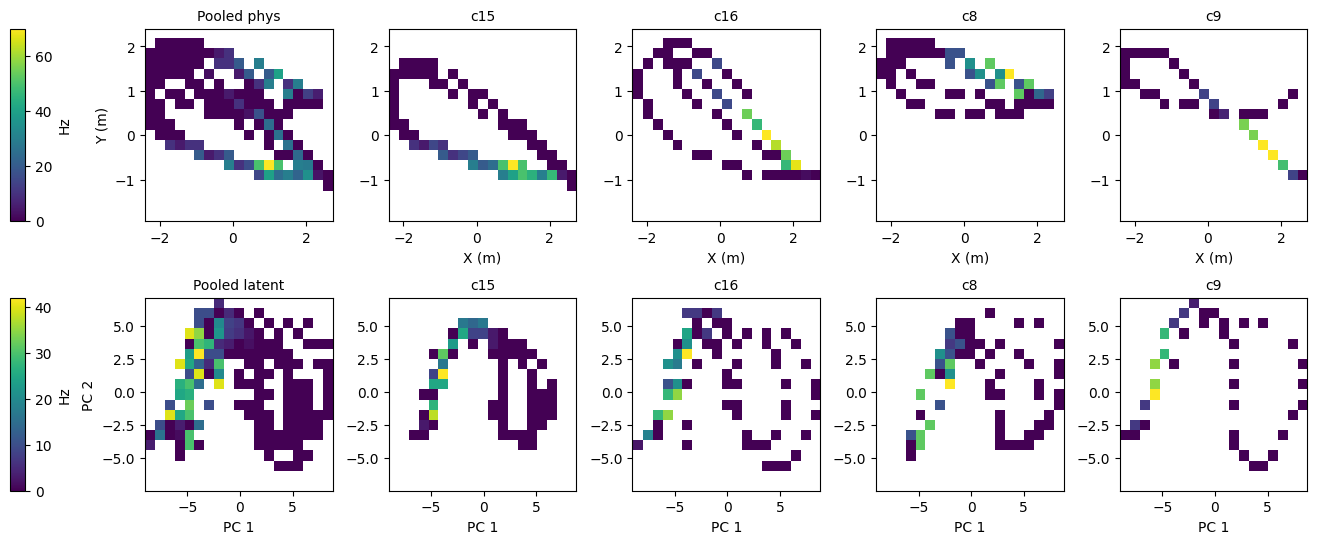

In [38]:
# example
session_to_analyze = 'Dataset_1_32622_231009' # 'Dataset_1_32622_231009', 'Dataset_3_14543_240421'
ind = 13 # 13, 81, 69, 12 # active_indices[ind_active]
loc_bin_width = None
num_of_bins = 20
dt = 0.1
rate_map_nan = True # If True, keep NaN values in rate map indicating the place never been visited
colorbar_label = 'Hz'
ft = ('Reward', 'Reward')
print(f'Session: {session_to_analyze}; Neuron: {ind}')

analyzer = BatSpatialInfo(
    session_id=session_to_analyze,
    all_session=all_session,
    all_xyz=all_xyz,
    pca_sub=all_latents_pca3,
    all_latents=all_latents,
    all_true_spike=all_true_spike,
    all_cluster_session=all_cluster_session,
    all_rel_time=all_rel_time, 
    all_reward=all_reward, 
    all_perch=all_perch,
)
results = analyzer.get_all_spatial_info()
loc_xyz_lim = np.stack((np.min(analyzer.xyz, axis=0), np.max(analyzer.xyz, axis=0)), axis=0) # shape: (2, 3)
loc_pca_3d_lim = np.stack((np.min(analyzer.pca_3d, axis=0), np.max(analyzer.pca_3d, axis=0)), axis=0)
ft_dict = results['flight_function_types'][ft]
clusters_in_ft = ft_dict['clusters']

fig, axes = plt.subplots(2, 5, figsize=(15, 6), gridspec_kw={'width_ratios': [3, 3, 3, 3, 3], 'wspace': 0.3, 'hspace': 0.4})
# STEP A: Compile Pooled Spikes/Coords for this Flight Function Type
ft_str = str(ft)
ft_mask = (analyzer.flight_types == ft_str)
spike_ft = analyzer.spikes[ft_mask]
coord_ft_phys = analyzer.xyz[ft_mask]
coord_ft_lat = analyzer.pca_3d[ft_mask]
# # Compute base SI over this functional category slice
# # Use fallback zeros if the array window has zero mean firing
# ft_si_phys = analyzer.compute_skaggs_si(coord_ft_phys, spike_ft, )[ind] if np.mean(spike_ft[:, ind]) > 0 else 0.0
# ft_si_lat = analyzer.compute_skaggs_si(coord_ft_lat, spike_ft, )[ind] if np.mean(spike_ft[:, ind]) > 0 else 0.0

# STEP B: Plot Physical Row for this Functional Type
# Col 0: Pooled Functional Type Map
row_phys = 0
ax_phys = axes[row_phys, 0]
x_edges, y_edges, rate_map, _ = generate_2d_rate_map(
    coord_ft_phys[:, 0], coord_ft_phys[:, 1], spike_ft[:, ind], 
    loc_xx_lim=loc_xyz_lim[:, 0], loc_yy_lim=loc_xyz_lim[:, 1], 
    loc_bin_width=loc_bin_width, num_of_bins=num_of_bins, dt=dt, rate_map_nan=rate_map_nan,
)
im_phys = ax_phys.imshow(rate_map.T, origin='lower', extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]], cmap='viridis', aspect='auto')
ax_phys.set_ylabel('Y (m)')
ax_phys.set_title(f"Pooled phys", fontsize=10)
# plt.colorbar(im, ax=ax_phys, label=colorbar_label)
# Cols 1+: Individual Clusters matching this Functional Type
for c_idx, clu in enumerate(clusters_in_ft.keys()):
    cluster_data = clusters_in_ft[clu]
    ax = axes[row_phys, c_idx + 1]
    x_edges, y_edges, rate_map, _ = generate_2d_rate_map(
        cluster_data['xyz'][:, 0], cluster_data['xyz'][:, 1], cluster_data['spikes'][:, ind], 
        loc_xx_lim=loc_xyz_lim[:, 0], loc_yy_lim=loc_xyz_lim[:, 1], 
        loc_bin_width=loc_bin_width, num_of_bins=num_of_bins, dt=dt, rate_map_nan=rate_map_nan,
    )
    im = ax.imshow(rate_map.T, origin='lower', extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]], cmap='viridis', aspect='auto')
    ax.set_xlabel('X (m)')
    ax.set_title(f"{clu.split('_')[-1]}", fontsize=10)
    # plt.colorbar(im, ax=ax, label=colorbar_label)

# STEP C: Plot Latent Row for this Functional Type
# Col 0: Pooled Functional Type Map
row_lat = 1
ax_lat = axes[row_lat, 0]
x_edges, y_edges, rate_map, _ = generate_2d_rate_map(
    coord_ft_lat[:, 0], coord_ft_lat[:, 1], spike_ft[:, ind], 
    loc_xx_lim=loc_pca_3d_lim[:, 0], loc_yy_lim=loc_pca_3d_lim[:, 1], 
    loc_bin_width=loc_bin_width, num_of_bins=num_of_bins, dt=dt, rate_map_nan=rate_map_nan,
)
im_lat = ax_lat.imshow(rate_map.T, origin='lower', extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]], cmap='viridis', aspect='auto')
ax_lat.set_ylabel('PC 2')
ax_lat.set_xlabel('PC 1')
ax_lat.set_title(f"Pooled latent", fontsize=10)
# plt.colorbar(im, ax=ax_lat, label=colorbar_label)
# Cols 1+: Individual Clusters matching this Functional Type
for c_idx, clu in enumerate(clusters_in_ft.keys()):
    cluster_data = clusters_in_ft[clu]
    ax = axes[row_lat, c_idx + 1]
    x_edges, y_edges, rate_map, _ = generate_2d_rate_map(
        cluster_data['pca_3d'][:, 0], cluster_data['pca_3d'][:, 1], cluster_data['spikes'][:, ind], 
        loc_xx_lim=loc_pca_3d_lim[:, 0], loc_yy_lim=loc_pca_3d_lim[:, 1], 
        loc_bin_width=loc_bin_width, num_of_bins=num_of_bins, dt=dt, rate_map_nan=rate_map_nan,
    )
    im = ax.imshow(rate_map.T, origin='lower', extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]], cmap='viridis', aspect='auto')
    ax.set_xlabel('PC 1')
    ax.set_title(f"{clu.split('_')[-1]}", fontsize=10)
    # plt.colorbar(im, ax=ax, label=colorbar_label)

# for ax in axes:
#     sns.despine(ax=ax, trim=True)
#     ax.grid(True)
# plt.tight_layout()
# 2. Add colorbars using explicit manual coordinates relative to the subplot axes
for ax, im in [(ax_phys, im_phys), (ax_lat, im_lat)]:
    pos = ax.get_position()  # [x0, y0, width, height]
    # Place colorbar just to the right of the subplot: [left, bottom, width, height]
    cax = fig.add_axes([pos.x0 - 0.09, pos.y0, 0.01, pos.height])
    fig.colorbar(im, cax=cax, label=colorbar_label)

# plt.savefig(f"./out-figures/fig4-example-single-unit.svg", dpi=300)
# plt.savefig(f"./out-figures/fig4-example-single-unit.png", dpi=300)

Session: Dataset_1_32622_231009; Neuron: 13


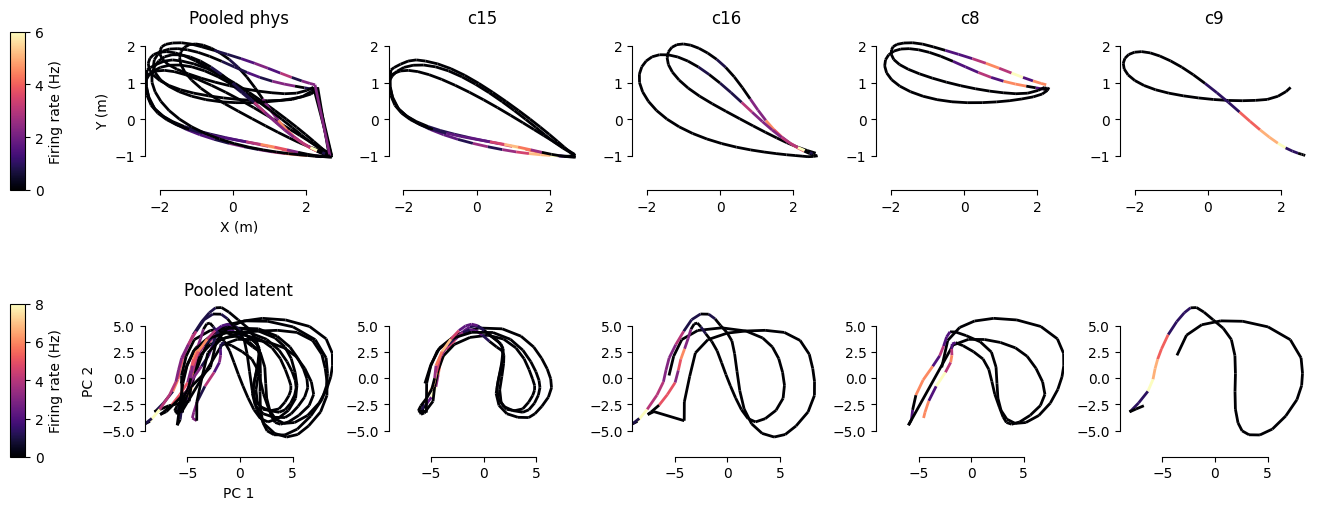

In [13]:
# example
session_to_analyze = 'Dataset_1_32622_231009' # 'Dataset_1_32622_231009', 'Dataset_3_14543_240421'
ind = 13 # 13, 81, 69, 12 # active_indices[ind_active]
loc_bin_width = None
num_of_bins = 20
dt = 0.1
rate_map_nan = True # If True, keep NaN values in rate map indicating the place never been visited
colorbar_label = 'Firing rate (Hz)'
ft = ('Reward', 'Reward')
print(f'Session: {session_to_analyze}; Neuron: {ind}')

analyzer = BatSpatialInfo(
    session_id=session_to_analyze,
    all_session=all_session,
    all_xyz=all_xyz,
    pca_sub=all_latents_pca3,
    all_latents=all_latents,
    all_true_spike=all_true_spike,
    all_cluster_session=all_cluster_session,
    all_rel_time=all_rel_time, 
    all_reward=all_reward, 
    all_perch=all_perch,
)
results = analyzer.get_all_spatial_info()
loc_xyz_lim = np.stack((np.min(analyzer.xyz, axis=0), np.max(analyzer.xyz, axis=0)), axis=0) # shape: (2, 3)
loc_pca_3d_lim = np.stack((np.min(analyzer.pca_3d, axis=0), np.max(analyzer.pca_3d, axis=0)), axis=0)
ft_dict = results['flight_function_types'][ft]
clusters_in_ft = ft_dict['clusters']

fig, axes = plt.subplots(2, 5, figsize=(15, 6), gridspec_kw={'width_ratios': [3, 3, 3, 3, 3], 'wspace': 0.3, 'hspace': 0.4})
# STEP A: Compile Pooled Spikes/Coords for this Flight Function Type
ft_str = str(ft)
ft_mask = (analyzer.flight_types == ft_str)
spike_ft = analyzer.spikes[ft_mask]
coord_ft_phys = analyzer.xyz[ft_mask]
coord_ft_lat = analyzer.pca_3d[ft_mask]
# # Compute base SI over this functional category slice
# # Use fallback zeros if the array window has zero mean firing
# ft_si_phys = analyzer.compute_skaggs_si(coord_ft_phys, spike_ft, )[ind] if np.mean(spike_ft[:, ind]) > 0 else 0.0
# ft_si_lat = analyzer.compute_skaggs_si(coord_ft_lat, spike_ft, )[ind] if np.mean(spike_ft[:, ind]) > 0 else 0.0

# STEP B: Plot Physical Row for this Functional Type
# Col 0: Pooled Functional Type Map
row_phys = 0
ax_phys = axes[row_phys, 0]
# 1. Prepare 2D line segments from trajectory points
x = coord_ft_phys[:, 0]
y = coord_ft_phys[:, 1]
spikes = spike_ft[:, ind]
loc_lim = np.copy(loc_xyz_lim)
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)
# 3. Create and add LineCollection
lc = LineCollection(segments, cmap='magma', linewidths=2)
lc.set_array(spikes)  # Color maps according to spike values
# lc.set_clim(vmin=0, vmax=spikes.max()) # Optional: set manual color scale limits
im_phys = ax_phys.add_collection(lc)
# 4. Set axes limits and labels
ax_phys.set_xlim(loc_lim[0, 0], loc_lim[1, 0])
ax_phys.set_ylim(loc_lim[0, 1], loc_lim[1, 1])
ax_phys.set_xlabel('X (m)')
ax_phys.set_ylabel('Y (m)')
ax_phys.set_title("Pooled phys")
ax_phys.set_aspect('equal')
sns.despine(ax=ax_phys, trim=True)

# Cols 1+: Individual Clusters matching this Functional Type
for c_idx, clu in enumerate(clusters_in_ft.keys()):
    cluster_data = clusters_in_ft[clu]
    ax = axes[row_phys, c_idx + 1]
    x = cluster_data['xyz'][:, 0]
    y = cluster_data['xyz'][:, 1]
    spikes = cluster_data['spikes'][:, ind]
    loc_lim = np.copy(loc_xyz_lim)
    points = np.array([x, y]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    # 3. Create and add LineCollection
    lc = LineCollection(segments, cmap='magma', linewidths=2)
    lc.set_array(spikes)  # Color maps according to spike values
    # lc.set_clim(vmin=0, vmax=spikes.max()) # Optional: set manual color scale limits
    im_phys = ax.add_collection(lc)
    # 4. Set axes limits and labels
    ax.set_xlim(loc_lim[0, 0], loc_lim[1, 0])
    ax.set_ylim(loc_lim[0, 1], loc_lim[1, 1])
    ax.set_title(f"{clu.split('_')[-1]}")
    ax.set_aspect('equal')
    sns.despine(ax=ax, trim=True)


# STEP C: Plot Latent Row for this Functional Type
# Col 0: Pooled Functional Type Map
row_lat = 1
ax_lat = axes[row_lat, 0]
x = coord_ft_lat[:, 0]
y = coord_ft_lat[:, 1]
spikes = spike_ft[:, ind]
loc_lim = np.copy(loc_pca_3d_lim)
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)
# 3. Create and add LineCollection
lc = LineCollection(segments, cmap='magma', linewidths=2)
lc.set_array(spikes)  # Color maps according to spike values
# lc.set_clim(vmin=0, vmax=spikes.max()) # Optional: set manual color scale limits
im_lat = ax_lat.add_collection(lc)
# 4. Set axes limits and labels
ax_lat.set_xlim(loc_lim[0, 0], loc_lim[1, 0])
ax_lat.set_ylim(loc_lim[0, 1], loc_lim[1, 1])
ax_lat.set_xlabel('PC 1')
ax_lat.set_ylabel('PC 2')
ax_lat.set_title("Pooled latent")
ax_lat.set_aspect('equal')
sns.despine(ax=ax_lat, trim=True)

# Cols 1+: Individual Clusters matching this Functional Type
for c_idx, clu in enumerate(clusters_in_ft.keys()):
    cluster_data = clusters_in_ft[clu]
    ax = axes[row_lat, c_idx + 1]
    x = cluster_data['pca_3d'][:, 0]
    y = cluster_data['pca_3d'][:, 1]
    spikes = cluster_data['spikes'][:, ind]
    loc_lim = np.copy(loc_pca_3d_lim)
    points = np.array([x, y]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    # 3. Create and add LineCollection
    lc = LineCollection(segments, cmap='magma', linewidths=2)
    lc.set_array(spikes)  # Color maps according to spike values
    # lc.set_clim(vmin=0, vmax=spikes.max()) # Optional: set manual color scale limits
    im_phys = ax.add_collection(lc)
    # 4. Set axes limits and labels
    ax.set_xlim(loc_lim[0, 0], loc_lim[1, 0])
    ax.set_ylim(loc_lim[0, 1], loc_lim[1, 1])
    # ax.set_title(f"{clu.split('_')[-1]}")
    ax.set_aspect('equal')
    sns.despine(ax=ax, trim=True)

# for ax in axes:
#     sns.despine(ax=ax, trim=True)
#     ax.grid(True)
# plt.tight_layout()
# 2. Add colorbars using explicit manual coordinates relative to the subplot axes
for ax, im in [(ax_phys, im_phys), (ax_lat, im_lat)]:
    pos = ax.get_position()  # [x0, y0, width, height]
    # Place colorbar just to the right of the subplot: [left, bottom, width, height]
    cax = fig.add_axes([pos.x0 - 0.09, pos.y0, 0.01, pos.height])
    fig.colorbar(im, cax=cax, label=colorbar_label)

# plt.savefig(f"./out-figures/fig4-example-single-unit.svg", dpi=300)
# plt.savefig(f"./out-figures/fig4-example-single-unit.png", dpi=300)

## Example - population vector

In [31]:
# example
session_to_analyze = 'Dataset_1_32622_231009' # 'Dataset_1_32622_231009', 'Dataset_3_14543_240421'
clu_1, clu_2 = session_to_analyze + '_c15', session_to_analyze + '_c16'  # Two selected flight geometry clusters
fl_1, fl_2 = 1, 1  # 0,1; 1,1; 2,1  Two selected flight trajectories from two clusters
fl_1_train = 2  # the selected flight trajectory to order neurons
rate_thresh = 1.0  # firing rate threshold for cell selection
si_thresh = 0.1 # SI threshold for cell selection
loc_bin_width = None
num_of_bins = 20
dt = 0.1
rate_map_nan = True # If True, keep NaN values in rate map indicating the place never been visited
colorbar_label = 'Hz'
ft = ('Reward', 'Reward')
print(f'Session: {session_to_analyze}')

analyzer = BatSpatialInfo(
    session_id=session_to_analyze,
    all_session=all_session,
    all_xyz=all_xyz,
    pca_sub=all_latents_pca3,
    all_latents=all_latents,
    all_true_spike=all_true_spike,
    all_cluster_session=all_cluster_session,
    all_rel_time=all_rel_time, 
    all_reward=all_reward, 
    all_perch=all_perch,
)
results = analyzer.get_all_spatial_info()
loc_xyz_lim = np.stack((np.min(analyzer.xyz, axis=0), np.max(analyzer.xyz, axis=0)), axis=0) # shape: (2, 3)
loc_pca_3d_lim = np.stack((np.min(analyzer.pca_3d, axis=0), np.max(analyzer.pca_3d, axis=0)), axis=0)
ft_dict = results['flight_function_types'][ft]
clusters_in_ft = ft_dict['clusters']
# Find indices where True blocks start and end
diff = np.diff(np.pad(clusters_in_ft[clu_1]['mask'].astype(int), (1, 1)))
starts = np.where(diff == 1)[0]
ends = np.where(diff == -1)[0]
indices_1 = np.arange(starts[fl_1], ends[fl_1])
indices_1_train = np.arange(starts[fl_1_train], ends[fl_1_train])
diff = np.diff(np.pad(clusters_in_ft[clu_2]['mask'].astype(int), (1, 1)))
starts = np.where(diff == 1)[0]
ends = np.where(diff == -1)[0]
indices_2 = np.arange(starts[fl_2], ends[fl_2])
ft_dict['clusters'][clu_1]['si_physical']
# rate
flight_spikes = analyzer.spikes[indices_1_train, :]
rate_mask = (np.sum(flight_spikes, axis=0) / (len(indices_1_train) * dt)) > rate_thresh
# SI
sis = np. min(np.array([analyzer.compute_skaggs_si(analyzer.xyz[indices, :], analyzer.spikes[indices, :]) for indices in [indices_1_train, indices_1, indices_2]]), axis=0)
si_mask = sis > si_thresh

Session: Dataset_1_32622_231009


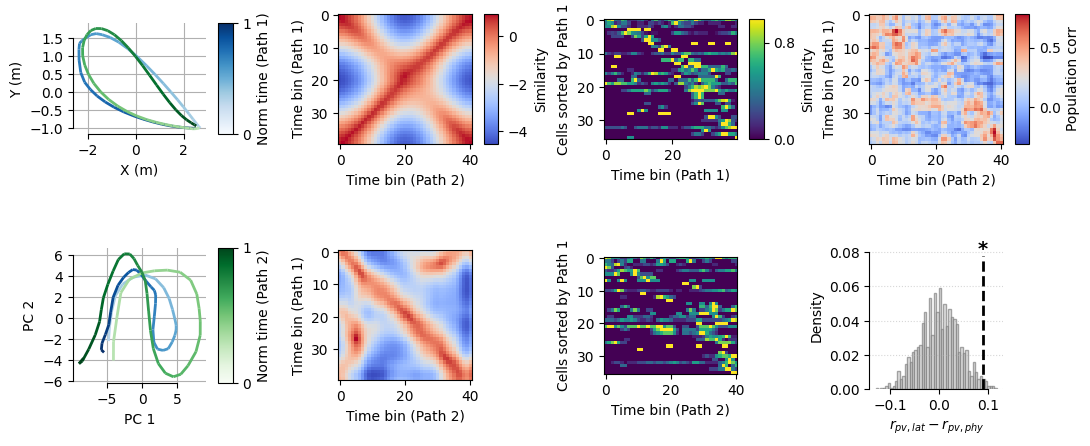

In [32]:
# plot
fig, axes = plt.subplots(2, 4, figsize=(12, 6), gridspec_kw={'width_ratios': [3, 3, 3, 3,], 'wspace': 0.99, 'hspace': 0.05})
# ================ first column: 2D scatter plot ==================
def plot_gradient_trace(ax, x, y, cmap_name='viridis'):
    """Helper function to plot a 2D line with a gradient color mapping."""
    points = np.array([x, y]).T.reshape(-1, 1, 2)
    # Create line segments connecting point (i) to point (i+1)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    # Normalize step indices from 0 (start) to 1 (end) for the colormap
    norm = np.linspace(0.3, 1, len(segments))
    lc = LineCollection(segments, cmap=cmap_name, norm=plt.Normalize(0, 1))
    lc.set_array(norm)
    lc.set_linewidth(2)
    ax.add_collection(lc)
    ax.autoscale() # Rescale axis limits to fit the segments
    return lc

ax = axes[0,0] # physical space
# Plot your traces with gradients 
lc = plot_gradient_trace(ax, analyzer.xyz[indices_1, 0], analyzer.xyz[indices_1, 1], cmap_name='Blues')
_ = plot_gradient_trace(ax, analyzer.xyz[indices_2, 0], analyzer.xyz[indices_2, 1], cmap_name='Greens')
ax.set_xlabel('X (m)')
ax.set_ylabel('Y (m)')
ax.grid(True)
ax.set_aspect(1.5)
sns.despine(ax=ax, trim=True)
# --- Add Colorbars 
pos = ax.get_position()  # [x0, y0, width, height]
cax = fig.add_axes([pos.x1 + 0.01, pos.y0, 0.012, pos.height])
cbar = fig.colorbar(lc, cax=cax, ticks=[0.0, 1.0])
cbar.set_label('Norm time (Path 1)')

ax = axes[1,0] # latent space
# Plot your traces with gradients 
_ = plot_gradient_trace(ax, analyzer.pca_3d[indices_1, 0], analyzer.pca_3d[indices_1, 1], cmap_name='Blues')
lc = plot_gradient_trace(ax, analyzer.pca_3d[indices_2, 0], analyzer.pca_3d[indices_2, 1], cmap_name='Greens')
ax.set_xlabel('PC 1')
ax.set_ylabel('PC 2')
ax.grid(True)
ax.set_aspect(1.5)
sns.despine(ax=ax, trim=True)
# --- Add Colorbars 
pos = ax.get_position()  # [x0, y0, width, height]
cax = fig.add_axes([pos.x1 + 0.01, pos.y0, 0.012, pos.height])
cbar = fig.colorbar(lc, cax=cax, ticks=[0.0, 1.0])
cbar.set_label('Norm time (Path 2)')


# ================ second column: similarity matrix ==================
ax = axes[0,1]  # physical space
# 1. Compute T x T pairwise Euclidean distances
dist_matrix = cdist(analyzer.xyz[indices_1, :], analyzer.xyz[indices_2, :], metric='euclidean')
# # 2. Convert distance to similarity (Gaussian kernel, adjust sigma to scale sensitivity)
# sigma = np.std(dist_matrix)  # or set a fixed value like 1.0
# sim_matrix = np.exp(-dist_matrix**2 / (2 * sigma**2))
sim_matrix_phy = 1.0 - dist_matrix
im = ax.imshow(sim_matrix_phy, cmap='coolwarm', aspect='equal')
ax.set_xlabel('Time bin (Path 2)')
ax.set_ylabel('Time bin (Path 1)')
# --- Add Colorbars 
pos = ax.get_position()  # [x0, y0, width, height]
cax = fig.add_axes([pos.x1 + 0.01, pos.y0, 0.012, pos.height])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Similarity')

ax = axes[1,1]  # latent space
# 1. Compute T x T pairwise Euclidean distances
dist_matrix = cdist(analyzer.pca_3d[indices_1, :], analyzer.pca_3d[indices_2, :], metric='euclidean')
# # 2. Convert distance to similarity (Gaussian kernel, adjust sigma to scale sensitivity)
# sigma = np.std(dist_matrix)  # or set a fixed value like 1.0
# sim_matrix = np.exp(-dist_matrix**2 / (2 * sigma**2))
sim_matrix_lat = 1.0 - dist_matrix
im = ax.imshow(sim_matrix_lat, cmap='coolwarm', aspect='equal')
ax.set_xlabel('Time bin (Path 2)')
ax.set_ylabel('Time bin (Path 1)')

# ================ third column: sorted response heatmap ==================
norm_spikes = []
peak_times = []
flight_spikes = analyzer.spikes[indices_1_train, :]
flight_spikes = flight_spikes[:, si_mask]
for cc in range(flight_spikes.shape[1]):
    curve = pd.Series(flight_spikes[:, cc]).rolling(window=2, min_periods=1, center=True).mean().values
    # curve = flight_spikes[:, cc]
    c_min, c_max = np.min(curve), np.max(curve)
    curve_norm = (curve - c_min) / (c_max - c_min + 1e-5)
    norm_spikes.append(curve_norm)
    peak_times.append(np.argmax(curve_norm))
norm_spikes = np.array(norm_spikes)
sort_order = np.argsort(peak_times)

ax = axes[0,2] # Path 1
norm_spikes = []
peak_times = []
flight_spikes = analyzer.spikes[indices_1, :]
flight_spikes = flight_spikes[:, si_mask]
for cc in range(flight_spikes.shape[1]):
    curve = pd.Series(flight_spikes[:, cc]).rolling(window=2, min_periods=1, center=True).mean().values
    # curve = flight_spikes[:, cc]
    c_min, c_max = np.min(curve), np.max(curve)
    curve_norm = (curve - c_min) / (c_max - c_min + 1e-5)
    norm_spikes.append(curve_norm)
    peak_times.append(np.argmax(curve_norm))
norm_spikes = np.array(norm_spikes)
sorted_raster1 = norm_spikes[sort_order, :]
sort_order1 = np.argsort(peak_times)
im = ax.imshow(sorted_raster1, cmap='viridis', aspect=1.0)
ax.set_xlabel('Time bin (Path 1)')
ax.set_ylabel('Cells sorted by Path 1')
# --- Add Colorbars 
pos = ax.get_position()  # [x0, y0, width, height]
cax = fig.add_axes([pos.x1 + 0.01, pos.y0, 0.012, pos.height])
cbar = fig.colorbar(im, cax=cax, ticks=[0.0, 0.8])
cbar.set_label('Similarity')

ax = axes[1,2] # Path 2
norm_spikes = []
peak_times = []
flight_spikes = analyzer.spikes[indices_2, :]
flight_spikes = flight_spikes[:, si_mask]
for cc in range(flight_spikes.shape[1]):
    curve = pd.Series(flight_spikes[:, cc]).rolling(window=2, min_periods=1, center=True).mean().values
    # curve = flight_spikes[:, cc]
    c_min, c_max = np.min(curve), np.max(curve)
    curve_norm = (curve - c_min) / (c_max - c_min + 1e-5)
    norm_spikes.append(curve_norm)
    peak_times.append(np.argmax(curve_norm))
norm_spikes = np.array(norm_spikes)
sorted_raster2 = norm_spikes[sort_order, :]
sort_order2 = np.argsort(peak_times)
im = ax.imshow(sorted_raster2, cmap='viridis', aspect=1.0)
ax.set_xlabel('Time bin (Path 2)')
ax.set_ylabel('Cells sorted by Path 1')

# ================ fourth column: population vector correlation  and spearman ==================
ax = axes[0,3]  # population vector correlation
# 1. Compute T x T pairwise Euclidean distances
dist_matrix = cdist(sorted_raster1.T, sorted_raster2.T, metric='correlation')
# # 2. Convert distance to similarity (Gaussian kernel, adjust sigma to scale sensitivity)
# sigma = np.std(dist_matrix)  # or set a fixed value like 1.0
# sim_matrix = np.exp(-dist_matrix**2 / (2 * sigma**2))
sim_matrix_pv = 1.0 - dist_matrix
im = ax.imshow(sim_matrix_pv, cmap='coolwarm', aspect='equal')
ax.set_xlabel('Time bin (Path 2)')
ax.set_ylabel('Time bin (Path 1)')
# --- Add Colorbars 
pos = ax.get_position()  # [x0, y0, width, height]
cax = fig.add_axes([pos.x1 + 0.01, pos.y0, 0.012, pos.height])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Population corr')

# ax = axes[1,3]  # Spearman rank correlation between sorted cell indices from two flights
# # 1. Compute real Spearman correlation
# real_corr, real_p = spearmanr(sort_order1, sort_order2)
# # 2. Compute Null Distribution via Permutations
# n_shuffles = 1000
# rng = np.random.default_rng(seed=42)
# null_corrs = np.zeros(n_shuffles)
# sort_order2_shuffled = np.array(sort_order2)
# for i in range(n_shuffles):
#     rng.shuffle(sort_order2_shuffled)
#     null_corrs[i], _ = spearmanr(sort_order1, sort_order2_shuffled)
# # 3. Calculate empirical two-tailed p-value
# p_val = np.mean(np.abs(null_corrs) >= np.abs(real_corr))
# # --- Plot Null Distribution and Real Value ---
# ax.hist(null_corrs, bins=50, color='lightgrey', 
#     edgecolor='gray', density=True, alpha=0.7, label='Null Distribution')
# # Plot real observed correlation line
# p_str = f"p = {p_val:.4f}" if p_val >= 0.0001 else "p < 0.0001"
# ax.axvline(real_corr, color='k', linestyle='--', linewidth=2, 
#     label=f'Observed (r = {real_corr:.3f}, {p_str})')
# ax.set_xlabel('Spearman Correlation (r)')
# ax.set_ylabel('Density')
# # ax.legend(loc='upper right', frameon=False, fontsize=9)
# ax.grid(axis='y', linestyle=':', alpha=0.5)
# ax.set_aspect(0.3)
# sns.despine(ax=ax, trim=True)

ax = axes[1,3] # Spearman rank correlation between sim_matrix_pv and sim_matrix_lat/sim_matrix_phy
# 1. Flatten matrices (All 40x41 = 1640 points are unique timepoint pairs)
pv_flat = sim_matrix_pv.ravel()
phy_flat = sim_matrix_phy.ravel()
lat_flat = sim_matrix_lat.ravel()
# 2. Compute observed Spearman correlations
r_phy, _ = spearmanr(pv_flat, phy_flat)
r_lat, _ = spearmanr(pv_flat, lat_flat)
delta_r_obs = r_lat - r_phy  # We expect this to be positive if r_lat > r_phy
# 3. Paired Permutation Test (Swapping phy and lat features under Null)
n_shuffles = 1000
rng = np.random.default_rng(seed=42)
null_delta_r = np.zeros(n_shuffles)
# Combine for row-wise swapping
stacked = np.vstack([phy_flat, lat_flat])
for i in range(n_shuffles):
    # Randomly flip (swap) phy and lat values for a random subset of points
    swap_mask = rng.integers(0, 2, size=len(phy_flat), dtype=bool)
    null_phy = np.where(swap_mask, stacked[1], stacked[0])
    null_lat = np.where(swap_mask, stacked[0], stacked[1])
    r_phy_null, _ = spearmanr(pv_flat, null_phy)
    r_lat_null, _ = spearmanr(pv_flat, null_lat)
    null_delta_r[i] = r_lat_null - r_phy_null
# p-value
# p_val = np.mean(null_delta_r >= delta_r_obs)
p_val = np.mean(np.abs(null_delta_r) >= np.abs(delta_r_obs))
# Plot Null Distribution Histogram
weights = np.ones_like(null_delta_r)/float(len(null_delta_r))
ax.hist(null_delta_r, bins=50, color='lightgrey', edgecolor='gray', weights=weights, alpha=0.7, label='Null')
# Plot Observed Difference Line
# p_str = f"p = {p_val:.4f}" if p_val >= 0.0001 else "p < 0.0001"
ax.axvline(delta_r_obs, ymin=0, ymax=0.9, color='k', linestyle='--', linewidth=2, label=f'{p_str}')
# # Annotate individual correlations on the plot
# ax.text(0.05, 0.92, f"$r_{{pv, phy}}$ = {r_phy:.3f}\n$r_{{pv, lat}}$ = {r_lat:.3f}", 
#     transform=ax.transAxes, fontsize=8, verticalalignment='top',
#     bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='none'))
# --- Annotate significance stars above the vertical line ---
ax.set_ylim(0, 0.08)
stars = stars_for_p(p_val)
if stars:
    ymin, ymax = ax.get_ylim()
    y_pos = ymax * 0.95
    ax.text(delta_r_obs, y_pos, stars, ha='center', 
        va='bottom', fontsize=14, fontweight='bold', color='k')
    # Expand y-limit slightly to prevent clipping top stars
    ax.set_ylim(top=ymax * 1.08)
# Formatting
ax.set_xlabel('$r_{pv, lat} - r_{pv, phy}$')
ax.set_ylabel('Density')
# ax.set_title('PV Alignment: Latent vs. Physical')
# ax.legend(loc='upper right', frameon=False)
ax.grid(axis='y', linestyle=':', alpha=0.5)
ax.set_aspect(3.5)
sns.despine(ax=ax, trim=True)

# plt.savefig(f"./out-figures/fig4-example-population-vector.svg", dpi=300)
# plt.savefig(f"./out-figures/fig4-example-population-vector.png", dpi=300)